In [1]:
import sys
import pandas as pd
import numpy as np
import sklearn
import shap
import joblib

print("✅ ML environment is ready!")
print("Python:", sys.version)
print("Python path:", sys.executable)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("SHAP:", shap.__version__)

✅ ML environment is ready!
Python: 3.13.5 | packaged by Anaconda, Inc. | (main, Jun 12 2025, 16:37:03) [MSC v.1929 64 bit (AMD64)]
Python path: c:\Users\sanik\MedExplain_AI\ml\.venv\Scripts\python.exe
Pandas: 3.0.5
NumPy: 2.5.2
Scikit-learn: 1.9.0
SHAP: 0.52.0


In [2]:
from pathlib import Path

# Current notebook location
NOTEBOOK_DIR = Path.cwd()

# diabetes project directory
DIABETES_DIR = NOTEBOOK_DIR.parent

# dataset directory
DATA_DIR = DIABETES_DIR / "data"

print("Notebook directory:")
print(NOTEBOOK_DIR)

print("\nDiabetes project directory:")
print(DIABETES_DIR)

print("\nData directory:")
print(DATA_DIR)

print("\nCSV files found:")

csv_files = list(DATA_DIR.glob("*.csv"))

for i, file in enumerate(csv_files, start=1):
    print(f"{i}. {file.name}")

Notebook directory:
c:\Users\sanik\MedExplain_AI\ml\diabetes\notebooks

Diabetes project directory:
c:\Users\sanik\MedExplain_AI\ml\diabetes

Data directory:
c:\Users\sanik\MedExplain_AI\ml\diabetes\data

CSV files found:
1. diabetes_binary_health_indicators_BRFSS2015.csv


In [3]:
# ============================================================
# STEP 3 — LOAD THE DIABETES DATASET
# ============================================================

DATA_FILE = DATA_DIR / "diabetes_binary_health_indicators_BRFSS2015.csv"

# Load CSV
df = pd.read_csv(DATA_FILE)

print("✅ Dataset loaded successfully!")
print()
print("Dataset shape:")
print(df.shape)

print()
print("Number of rows:", f"{df.shape[0]:,}")
print("Number of columns:", df.shape[1])

✅ Dataset loaded successfully!

Dataset shape:
(253680, 22)

Number of rows: 253,680
Number of columns: 22


In [4]:
# ============================================================
# STEP 4 — FIRST LOOK AT THE DATA
# ============================================================

df.head()

,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


In [5]:
# ============================================================
# STEP 5 — DATASET STRUCTURE & FEATURE INFORMATION
# ============================================================

print("Dataset Information")
print("=" * 60)

print("\nColumn names:")
for i, column in enumerate(df.columns, start=1):
    print(f"{i:2}. {column}")

print("\n\nData types:")
print(df.dtypes)

print("\n\nDataset info:")
df.info()

Dataset Information

Column names:
 1. Diabetes_binary
 2. HighBP
 3. HighChol
 4. CholCheck
 5. BMI
 6. Smoker
 7. Stroke
 8. HeartDiseaseorAttack
 9. PhysActivity
10. Fruits
11. Veggies
12. HvyAlcoholConsump
13. AnyHealthcare
14. NoDocbcCost
15. GenHlth
16. MentHlth
17. PhysHlth
18. DiffWalk
19. Sex
20. Age
21. Education
22. Income


Data types:
Diabetes_binary         float64
HighBP                  float64
HighChol                float64
CholCheck               float64
BMI                     float64
Smoker                  float64
Stroke                  float64
HeartDiseaseorAttack    float64
PhysActivity            float64
Fruits                  float64
Veggies                 float64
HvyAlcoholConsump       float64
AnyHealthcare           float64
NoDocbcCost             float64
GenHlth                 float64
MentHlth                float64
PhysHlth                float64
DiffWalk                float64
Sex                     float64
Age                     float64
Education 

In [6]:
# ============================================================
# STEP 6 — MISSING VALUE ANALYSIS
# ============================================================

missing = df.isnull().sum()

missing_table = pd.DataFrame({
    "Missing Values": missing,
    "Missing Percentage": (missing / len(df) * 100).round(2)
})

missing_table = missing_table.sort_values(
    by="Missing Values",
    ascending=False
)

missing_table

,Missing Values,Missing Percentage
Diabetes_binary,0,0.0
HighBP,0,0.0
HighChol,0,0.0
CholCheck,0,0.0
BMI,0,0.0
Smoker,0,0.0
Stroke,0,0.0
HeartDiseaseorAttack,0,0.0
PhysActivity,0,0.0
Fruits,0,0.0


In [7]:
# ============================================================
# STEP 7 — DUPLICATE RECORDS
# ============================================================

duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)
print(
    "Duplicate percentage:",
    round(duplicate_count / len(df) * 100, 2),
    "%"
)

Number of duplicate rows: 24206
Duplicate percentage: 9.54 %


In [8]:
# ============================================================
# STEP 8 — TARGET VARIABLE ANALYSIS
# ============================================================

target = "Diabetes_binary"

print("Target variable:", target)
print()

print("Unique values:")
print(df[target].unique())

print("\nTarget distribution:")
print(df[target].value_counts())

print("\nTarget distribution (%):")
print(
    (df[target].value_counts(normalize=True) * 100)
    .round(2)
)

Target variable: Diabetes_binary

Unique values:
[0. 1.]

Target distribution:
Diabetes_binary
0.0    218334
1.0     35346
Name: count, dtype: int64

Target distribution (%):
Diabetes_binary
0.0    86.07
1.0    13.93
Name: proportion, dtype: float64


In [9]:
# ============================================================
# STEP 9 — UNIQUE VALUES FOR EACH FEATURE
# ============================================================

unique_summary = pd.DataFrame({
    "Feature": df.columns,
    "Unique Values": [
        df[column].nunique()
        for column in df.columns
    ],
    "Values": [
        sorted(df[column].dropna().unique().tolist())
        for column in df.columns
    ]
})

unique_summary

,Feature,Unique Values,Values
0,Diabetes_binary,2,"[0.0, 1.0]"
1,HighBP,2,"[0.0, 1.0]"
2,HighChol,2,"[0.0, 1.0]"
3,CholCheck,2,"[0.0, 1.0]"
4,BMI,84,"[12.0, 13.0, 14.0, 15.0, 16.0, 17.0, 18.0, 19...."
5,Smoker,2,"[0.0, 1.0]"
6,Stroke,2,"[0.0, 1.0]"
7,HeartDiseaseorAttack,2,"[0.0, 1.0]"
8,PhysActivity,2,"[0.0, 1.0]"
9,Fruits,2,"[0.0, 1.0]"


In [10]:
# ============================================================
# STEP 10 — SEPARATE TARGET AND FEATURES
# ============================================================

target = "Diabetes_binary"

X = df.drop(columns=[target])
y = df[target]

print("Target variable:", target)
print("Number of features:", X.shape[1])
print("Number of samples:", X.shape[0])

print("\nFeature columns:")
print(X.columns.tolist())

print("\nTarget values:")
print(y.unique())

Target variable: Diabetes_binary
Number of features: 21
Number of samples: 253680

Feature columns:
['HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']

Target values:
[0. 1.]


Diabetes class distribution
Class 0: 218,334 samples (86.07%)
Class 1: 35,346 samples (13.93%)


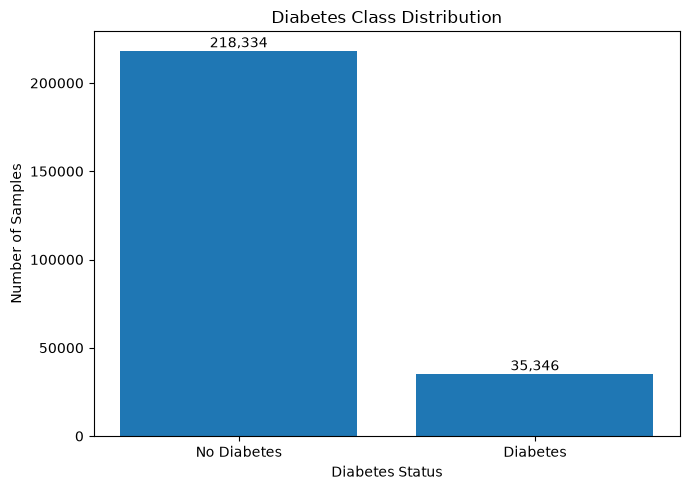

In [11]:
# ============================================================
# STEP 11 — TARGET CLASS DISTRIBUTION
# ============================================================

import matplotlib.pyplot as plt

class_counts = y.value_counts().sort_index()
class_percent = y.value_counts(normalize=True).sort_index() * 100

print("Diabetes class distribution")
print("=" * 50)

for value in class_counts.index:
    print(
        f"Class {int(value)}: "
        f"{class_counts[value]:,} samples "
        f"({class_percent[value]:.2f}%)"
    )

plt.figure(figsize=(7, 5))

bars = plt.bar(
    ["No Diabetes", "Diabetes"],
    class_counts.values
)

plt.title("Diabetes Class Distribution")
plt.xlabel("Diabetes Status")
plt.ylabel("Number of Samples")

for bar, count in zip(bars, class_counts.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{count:,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [12]:
# ============================================================
# STEP 12 — FEATURE VALUE DISTRIBUTIONS
# ============================================================

feature_columns = X.columns

for column in feature_columns:
    
    print("\n" + "=" * 60)
    print(column)
    print("=" * 60)
    
    print(
        X[column].value_counts(dropna=False).sort_index()
    )


HighBP
HighBP
0.0    144851
1.0    108829
Name: count, dtype: int64

HighChol
HighChol
0.0    146089
1.0    107591
Name: count, dtype: int64

CholCheck
CholCheck
0.0      9470
1.0    244210
Name: count, dtype: int64

BMI
BMI
12.0      6
13.0     21
14.0     41
15.0    132
16.0    348
       ... 
91.0      1
92.0     32
95.0     12
96.0      1
98.0      7
Name: count, Length: 84, dtype: int64

Smoker
Smoker
0.0    141257
1.0    112423
Name: count, dtype: int64

Stroke
Stroke
0.0    243388
1.0     10292
Name: count, dtype: int64

HeartDiseaseorAttack
HeartDiseaseorAttack
0.0    229787
1.0     23893
Name: count, dtype: int64

PhysActivity
PhysActivity
0.0     61760
1.0    191920
Name: count, dtype: int64

Fruits
Fruits
0.0     92782
1.0    160898
Name: count, dtype: int64

Veggies
Veggies
0.0     47839
1.0    205841
Name: count, dtype: int64

HvyAlcoholConsump
HvyAlcoholConsump
0.0    239424
1.0     14256
Name: count, dtype: int64

AnyHealthcare
AnyHealthcare
0.0     12417
1.0    241263


Binary features:
['HighBP', 'HighChol', 'CholCheck', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'DiffWalk', 'Sex']


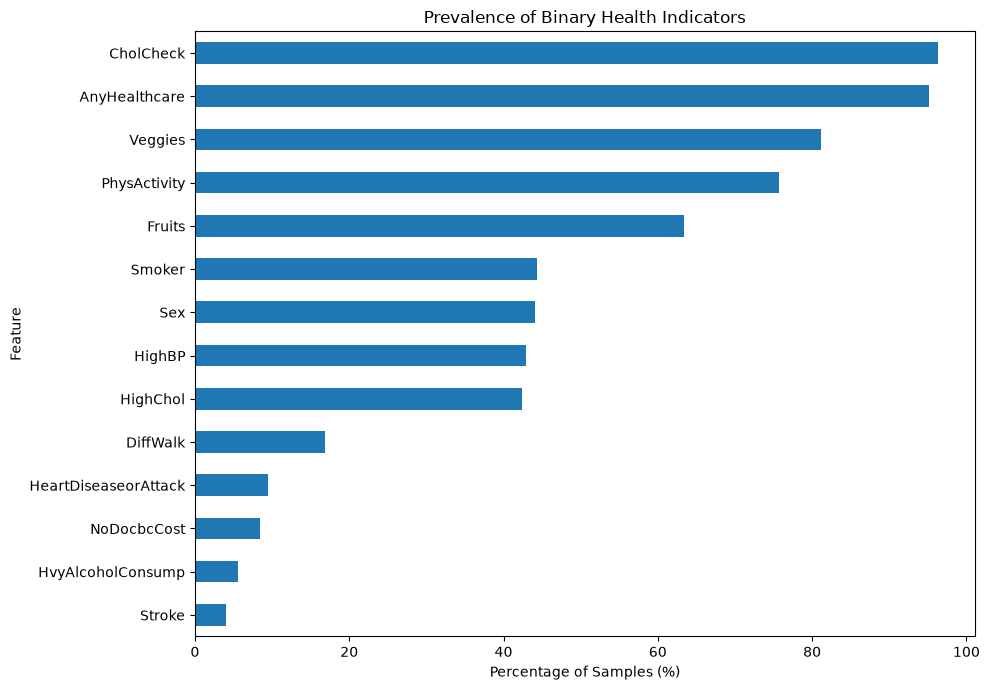

In [13]:
# ============================================================
# STEP 13 — PREVALENCE OF BINARY HEALTH INDICATORS
# ============================================================

binary_features = []

for column in X.columns:
    unique_values = set(X[column].dropna().unique())
    
    if unique_values.issubset({0, 1}):
        binary_features.append(column)

print("Binary features:")
print(binary_features)

prevalence = (
    X[binary_features]
    .mean()
    .sort_values(ascending=False)
    * 100
)

plt.figure(figsize=(10, 7))

prevalence.sort_values().plot(
    kind="barh"
)

plt.title("Prevalence of Binary Health Indicators")
plt.xlabel("Percentage of Samples (%)")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [14]:
# ============================================================
# STEP 14 — FEATURE VS DIABETES RATE
# ============================================================

comparison_results = []

for column in binary_features:
    
    rates = df.groupby(column)[target].mean() * 100
    
    if 0 in rates.index and 1 in rates.index:
        comparison_results.append({
            "Feature": column,
            "Diabetes Rate when 0 (%)": rates[0],
            "Diabetes Rate when 1 (%)": rates[1],
            "Difference (%)": rates[1] - rates[0]
        })

comparison_df = pd.DataFrame(comparison_results)

comparison_df = comparison_df.sort_values(
    by="Difference (%)",
    ascending=False
)

comparison_df

,Feature,Diabetes Rate when 0 (%),Diabetes Rate when 1 (%),Difference (%)
5,HeartDiseaseorAttack,11.953679,32.972000,21.018321
12,DiffWalk,10.532926,30.746339,20.213413
4,Stroke,13.179779,31.752818,18.573039
0,HighBP,6.035167,24.445690,18.410523
1,HighChol,7.981436,22.014853,14.033417
2,CholCheck,2.544879,14.374923,11.830045
3,Smoker,12.055332,16.292929,4.237598
11,NoDocbcCost,13.603299,17.523649,3.920350
10,AnyHealthcare,11.452042,14.061004,2.608962
13,Sex,12.967867,15.160332,2.192464


Correlation with Diabetes_binary


,Correlation
GenHlth,0.293569
HighBP,0.263129
DiffWalk,0.218344
BMI,0.216843
HighChol,0.200276
Age,0.177442
HeartDiseaseorAttack,0.177282
PhysHlth,0.171337
Stroke,0.105816
MentHlth,0.069315


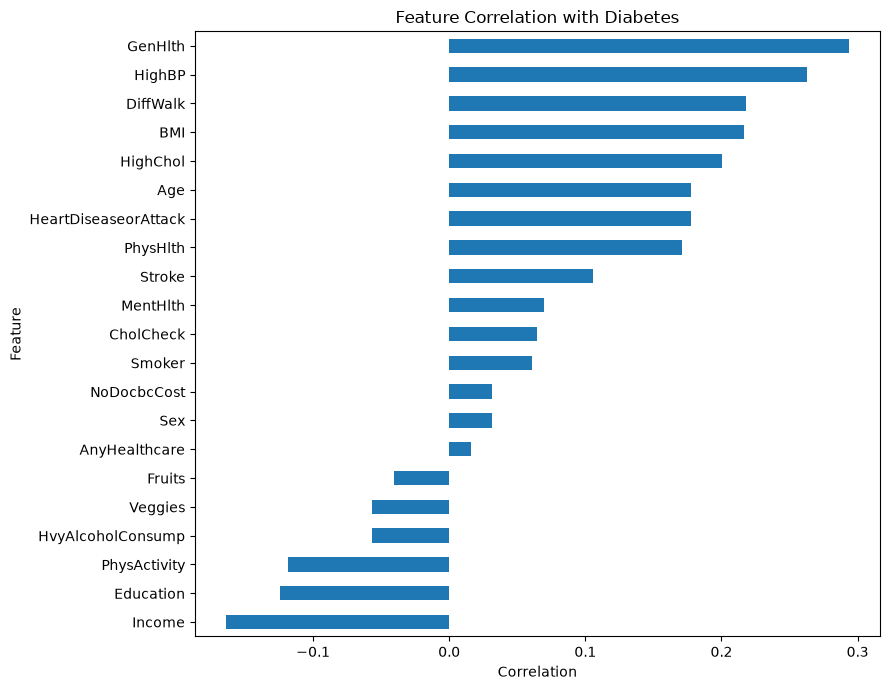

In [15]:
# ============================================================
# STEP 15 — CORRELATION WITH DIABETES
# ============================================================

correlation_with_target = (
    df.corr(numeric_only=True)[target]
    .drop(target)
    .sort_values(ascending=False)
)

print("Correlation with Diabetes_binary")
print("=" * 60)

display(
    correlation_with_target.to_frame(
        name="Correlation"
    )
)


# ============================================================
# VISUALIZATION
# ============================================================

plt.figure(figsize=(9, 7))

correlation_with_target.sort_values().plot(
    kind="barh"
)

plt.title("Feature Correlation with Diabetes")
plt.xlabel("Correlation")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

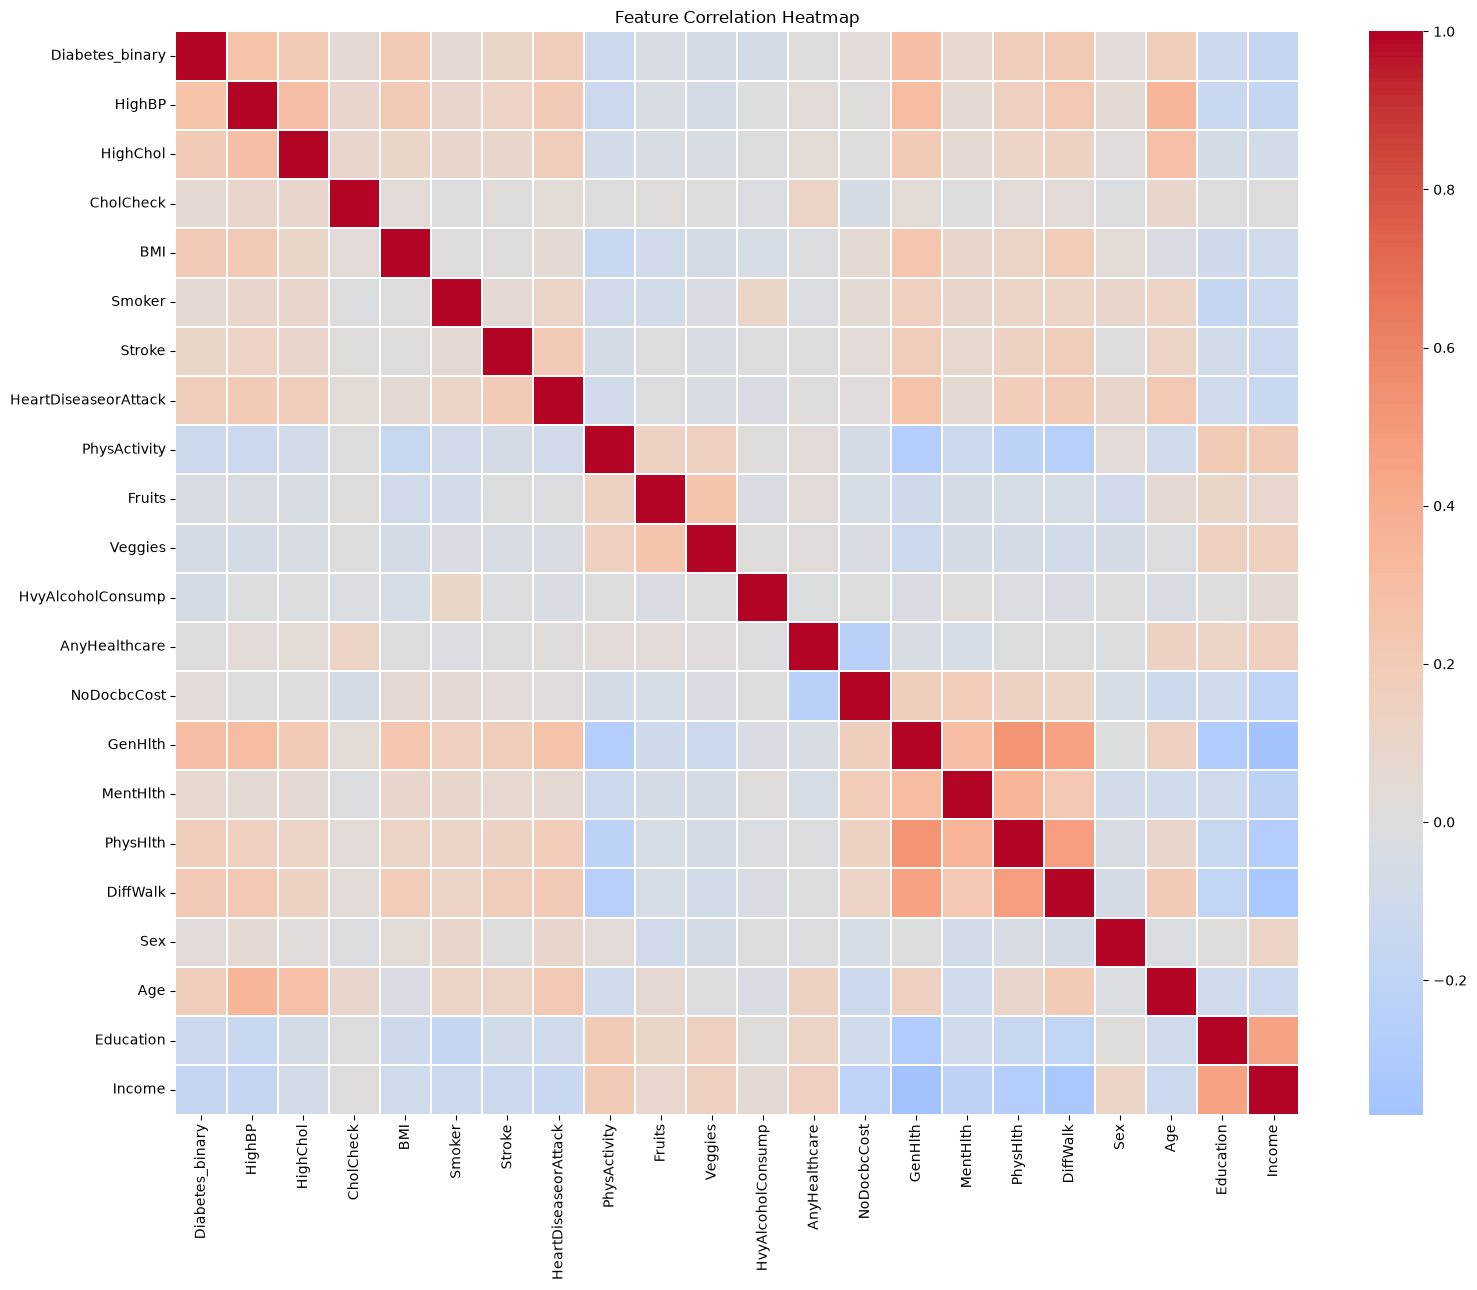

In [16]:
# ============================================================
# STEP 16 — CORRELATION HEATMAP
# ============================================================

import seaborn as sns

correlation_matrix = df.corr(numeric_only=True)

plt.figure(figsize=(16, 13))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    linewidths=0.3
)

plt.title("Feature Correlation Heatmap")

plt.tight_layout()
plt.show()

BMI statistics
count    253680.000000
mean         28.382364
std           6.608694
min          12.000000
25%          24.000000
50%          27.000000
75%          31.000000
max          98.000000
Name: BMI, dtype: float64


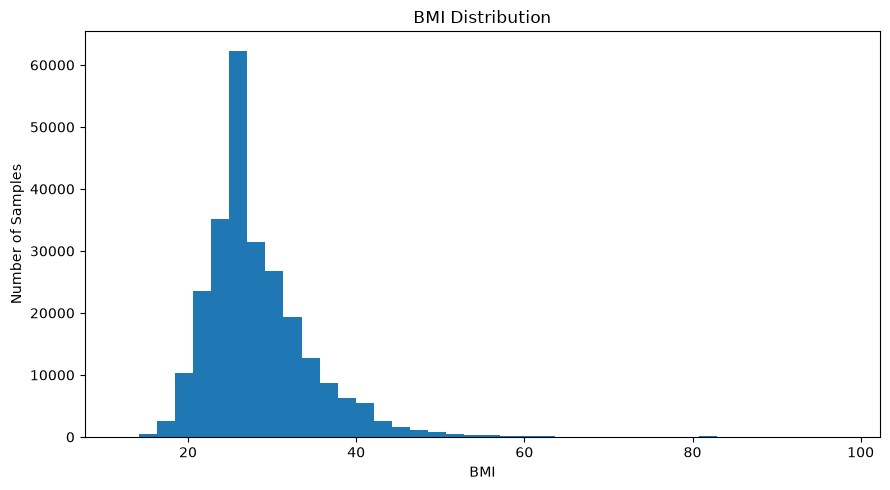

In [17]:
# ============================================================
# STEP 17 — BMI DISTRIBUTION
# ============================================================

print("BMI statistics")
print("=" * 50)

print(X["BMI"].describe())

plt.figure(figsize=(9, 5))

plt.hist(
    X["BMI"],
    bins=40
)

plt.title("BMI Distribution")
plt.xlabel("BMI")
plt.ylabel("Number of Samples")

plt.tight_layout()
plt.show()

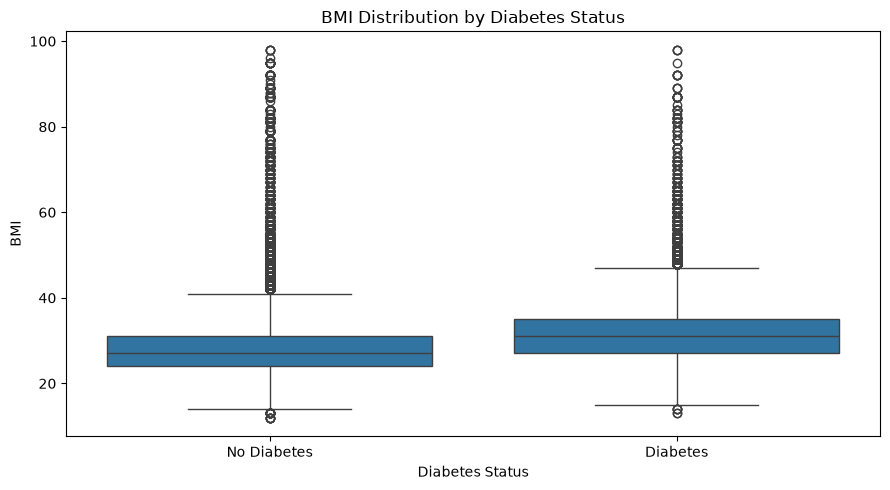

In [18]:
# ============================================================
# STEP 18 — BMI VS DIABETES
# ============================================================

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x=target,
    y="BMI"
)

plt.title("BMI Distribution by Diabetes Status")
plt.xlabel("Diabetes Status")
plt.ylabel("BMI")

plt.xticks(
    [0, 1],
    ["No Diabetes", "Diabetes"]
)

plt.tight_layout()
plt.show()

Age statistics
count    253680.000000
mean          8.032119
std           3.054220
min           1.000000
25%           6.000000
50%           8.000000
75%          10.000000
max          13.000000
Name: Age, dtype: float64


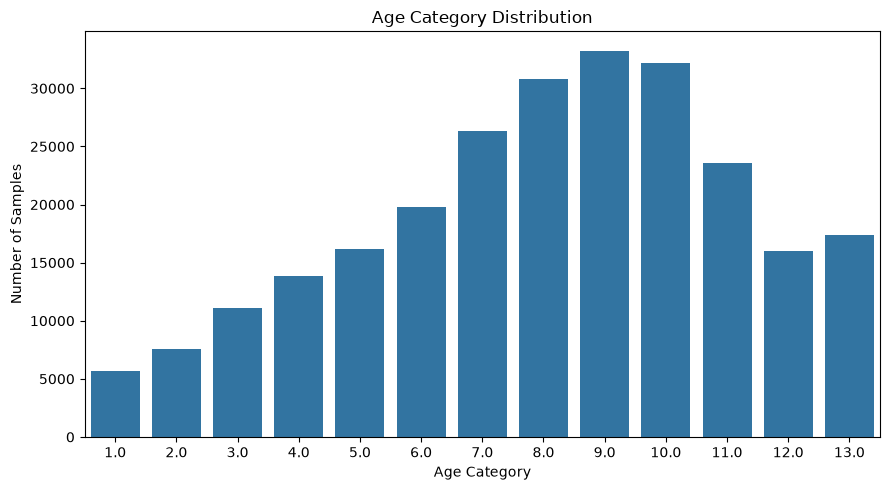

In [19]:
# ============================================================
# STEP 19 — AGE DISTRIBUTION
# ============================================================

print("Age statistics")
print("=" * 50)

print(X["Age"].describe())

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Age"
)

plt.title("Age Category Distribution")
plt.xlabel("Age Category")
plt.ylabel("Number of Samples")

plt.tight_layout()
plt.show()

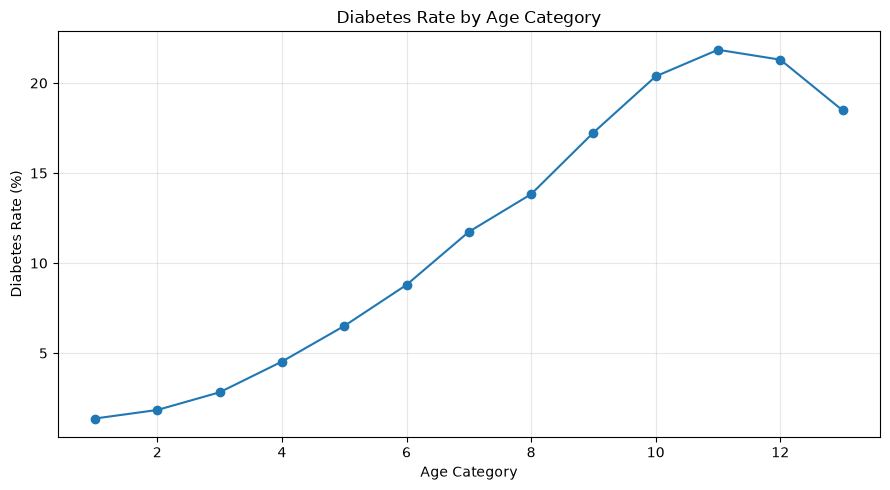

In [20]:
# ============================================================
# STEP 20 — DIABETES RATE BY AGE CATEGORY
# ============================================================

age_diabetes_rate = (
    df.groupby("Age")[target]
    .mean()
    * 100
)

plt.figure(figsize=(9, 5))

age_diabetes_rate.plot(
    marker="o"
)

plt.title("Diabetes Rate by Age Category")
plt.xlabel("Age Category")
plt.ylabel("Diabetes Rate (%)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [21]:
# ============================================================
# STEP 21 — EDA SUMMARY
# ============================================================

print("=" * 70)
print("DIABETES DATASET — EDA SUMMARY")
print("=" * 70)

print("\nDataset:")
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")

print("\nTarget:")
print(f"Target column: {target}")

print("\nMissing values:")
print(f"Total missing values: {df.isnull().sum().sum():,}")

print("\nDuplicate rows:")
print(f"Duplicate rows: {df.duplicated().sum():,}")

print("\nTarget distribution:")
for value in sorted(y.unique()):
    count = (y == value).sum()
    percentage = (y == value).mean() * 100
    
    label = "Diabetes" if value == 1 else "No Diabetes"
    
    print(
        f"{label}: {count:,} "
        f"({percentage:.2f}%)"
    )

print("\nNumber of binary features:")
print(len(binary_features))

print("\nTop features associated with diabetes:")
print(correlation_with_target.head(10))

print("\nEDA completed.")

DIABETES DATASET — EDA SUMMARY

Dataset:
Rows: 253,680
Columns: 22

Target:
Target column: Diabetes_binary

Missing values:
Total missing values: 0

Duplicate rows:
Duplicate rows: 24,206

Target distribution:
No Diabetes: 218,334 (86.07%)
Diabetes: 35,346 (13.93%)

Number of binary features:
14

Top features associated with diabetes:
GenHlth                 0.293569
HighBP                  0.263129
DiffWalk                0.218344
BMI                     0.216843
HighChol                0.200276
Age                     0.177442
HeartDiseaseorAttack    0.177282
PhysHlth                0.171337
Stroke                  0.105816
MentHlth                0.069315
Name: Diabetes_binary, dtype: float64

EDA completed.


In [22]:
# ============================================================
# STEP 22 — DUPLICATE RECORD ANALYSIS
# ============================================================

duplicate_mask = df.duplicated(keep=False)

duplicate_rows = df[duplicate_mask]

print("Total duplicate-related rows:", len(duplicate_rows))
print("Total duplicate groups/rows marked as duplicates:", df.duplicated().sum())

print("\nPercentage of duplicate rows:")
print(
    round(df.duplicated().sum() / len(df) * 100, 2),
    "%"
)

print("\nTarget distribution among duplicate-related rows:")
print(
    duplicate_rows[target]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nTarget distribution among non-duplicate rows:")
print(
    df[~duplicate_mask][target]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Total duplicate-related rows: 35575
Total duplicate groups/rows marked as duplicates: 24206

Percentage of duplicate rows:
9.54 %

Target distribution among duplicate-related rows:
Diabetes_binary
0.0    98.65
1.0     1.35
Name: proportion, dtype: float64

Target distribution among non-duplicate rows:
Diabetes_binary
0.0    84.01
1.0    15.99
Name: proportion, dtype: float64


In [23]:
# ============================================================
# STEP 23 — REMOVE EXACT DUPLICATES
# ============================================================

df_clean = df.drop_duplicates().copy()

print("Original dataset shape:")
print(df.shape)

print("\nCleaned dataset shape:")
print(df_clean.shape)

print("\nRows removed:")
print(len(df) - len(df_clean))

print("\nRemaining duplicates:")
print(df_clean.duplicated().sum())

Original dataset shape:
(253680, 22)

Cleaned dataset shape:
(229474, 22)

Rows removed:
24206

Remaining duplicates:
0


In [24]:
# ============================================================
# STEP 24 — TARGET DISTRIBUTION AFTER CLEANING
# ============================================================

clean_target_distribution = (
    df_clean[target]
    .value_counts()
    .sort_index()
)

clean_target_percentage = (
    df_clean[target]
    .value_counts(normalize=True)
    .sort_index()
    * 100
)

print("Target distribution after removing duplicates")
print("=" * 60)

for value in clean_target_distribution.index:

    label = "Diabetes" if value == 1 else "No Diabetes"

    print(
        f"{label}: "
        f"{clean_target_distribution[value]:,} "
        f"({clean_target_percentage[value]:.2f}%)"
    )

Target distribution after removing duplicates
No Diabetes: 194,377 (84.71%)
Diabetes: 35,097 (15.29%)


In [25]:
# ============================================================
# STEP 25 — FEATURES AND TARGET AFTER CLEANING
# ============================================================

X = df_clean.drop(columns=[target])
y = df_clean[target]

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeatures:")
print(X.columns.tolist())

Feature matrix shape: (229474, 21)
Target shape: (229474,)

Features:
['HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']


In [26]:
# ============================================================
# STEP 26 — TRAIN / TEST SPLIT
# ============================================================

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nTesting set:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

print("\nTraining target distribution:")
print(
    y_train.value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nTesting target distribution:")
print(
    y_test.value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Training set:
X_train: (183579, 21)
y_train: (183579,)

Testing set:
X_test: (45895, 21)
y_test: (45895,)

Training target distribution:
Diabetes_binary
0.0    84.71
1.0    15.29
Name: proportion, dtype: float64

Testing target distribution:
Diabetes_binary
0.0    84.71
1.0    15.29
Name: proportion, dtype: float64


In [27]:
# ============================================================
# STEP 27 — CHECK TRAIN/TEST OVERLAP
# ============================================================

train_indices = set(X_train.index)
test_indices = set(X_test.index)

overlap = train_indices.intersection(test_indices)

print("Number of overlapping records:")
print(len(overlap))

if len(overlap) == 0:
    print("✅ No train/test index overlap.")
else:
    print("⚠️ Potential data leakage detected.")

Number of overlapping records:
0
✅ No train/test index overlap.


In [28]:
# ============================================================
# STEP 28 — IDENTIFY FEATURE TYPES
# ============================================================

binary_features = []
numeric_features = []

for column in X_train.columns:

    unique_values = set(
        X_train[column].dropna().unique()
    )

    if unique_values.issubset({0, 1}):
        binary_features.append(column)
    else:
        numeric_features.append(column)

print("Binary features:")
print(binary_features)

print("\nNumber of binary features:", len(binary_features))

print("\nNon-binary/numeric features:")
print(numeric_features)

print("\nNumber of non-binary features:", len(numeric_features))

Binary features:
['HighBP', 'HighChol', 'CholCheck', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'DiffWalk', 'Sex']

Number of binary features: 14

Non-binary/numeric features:
['BMI', 'GenHlth', 'MentHlth', 'PhysHlth', 'Age', 'Education', 'Income']

Number of non-binary features: 7


In [29]:
# ============================================================
# STEP 29 — NON-BINARY FEATURE SUMMARY
# ============================================================

numeric_summary = X_train[numeric_features].describe().T

numeric_summary

,count,mean,std,min,25%,50%,75%,max
BMI,183579.0,28.676237,6.767845,12.0,24.0,27.0,32.0,98.0
GenHlth,183579.0,2.600248,1.065069,1.0,2.0,3.0,3.0,5.0
MentHlth,183579.0,3.518485,7.728498,0.0,0.0,0.0,2.0,30.0
PhysHlth,183579.0,4.678122,9.047791,0.0,0.0,0.0,4.0,30.0
Age,183579.0,8.083027,3.090490,1.0,6.0,8.0,10.0,13.0
Education,183579.0,4.979437,0.992968,1.0,4.0,5.0,6.0,6.0
Income,183579.0,5.891142,2.092419,1.0,5.0,6.0,8.0,8.0


In [30]:
# ============================================================
# STEP 30 — PREPARE DATA FOR MODEL TRAINING
# ============================================================

from sklearn.model_selection import train_test_split

# Target
target = "Diabetes_binary"

# Use the cleaned dataset
X = df_clean.drop(columns=[target])
y = df_clean[target]

# Identify binary and non-binary features again
binary_features = []
numeric_features = []

for column in X.columns:

    unique_values = set(X[column].dropna().unique())

    if unique_values.issubset({0, 1}):
        binary_features.append(column)
    else:
        numeric_features.append(column)

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("=" * 60)
print("DATA READY FOR MODEL TRAINING")
print("=" * 60)

print("\nFull dataset:")
print("X:", X.shape)
print("y:", y.shape)

print("\nTraining set:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nTesting set:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

print("\nBinary features:", len(binary_features))
print("Non-binary features:", len(numeric_features))

print("\nBinary features:")
print(binary_features)

print("\nNon-binary features:")
print(numeric_features)

DATA READY FOR MODEL TRAINING

Full dataset:
X: (229474, 21)
y: (229474,)

Training set:
X_train: (183579, 21)
y_train: (183579,)

Testing set:
X_test: (45895, 21)
y_test: (45895,)

Binary features: 14
Non-binary features: 7

Binary features:
['HighBP', 'HighChol', 'CholCheck', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'DiffWalk', 'Sex']

Non-binary features:
['BMI', 'GenHlth', 'MentHlth', 'PhysHlth', 'Age', 'Education', 'Income']


In [31]:
# ============================================================
# STEP 31 — LOGISTIC REGRESSION BASELINE MODEL
# ============================================================

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# ------------------------------------------------------------
# 1. Preprocessing
# ------------------------------------------------------------

preprocessor = ColumnTransformer(
    transformers=[
        # Standardize non-binary features
        (
            "numeric",
            StandardScaler(),
            numeric_features
        ),

        # Keep binary features as 0/1
        (
            "binary",
            "passthrough",
            binary_features
        )
    ]
)


# ------------------------------------------------------------
# 2. Create Logistic Regression pipeline
# ------------------------------------------------------------

logistic_model = Pipeline(
    steps=[
        (
            "preprocessing",
            preprocessor
        ),

        (
            "model",
            LogisticRegression(
                max_iter=1000,
                random_state=42
            )
        )
    ]
)


# ------------------------------------------------------------
# 3. Train
# ------------------------------------------------------------

print("Training Logistic Regression...")

logistic_model.fit(
    X_train,
    y_train
)

print("✅ Logistic Regression trained successfully!")

Training Logistic Regression...
✅ Logistic Regression trained successfully!


In [32]:
# ============================================================
# STEP 32 — MAKE PREDICTIONS
# ============================================================

# Predicted class
y_pred = logistic_model.predict(X_test)

# Predicted probability of diabetes
y_probability = logistic_model.predict_proba(X_test)[:, 1]

print("✅ Predictions generated!")

print("\nFirst 10 predicted classes:")
print(y_pred[:10])

print("\nFirst 10 diabetes probabilities:")
print(np.round(y_probability[:10], 4))

✅ Predictions generated!

First 10 predicted classes:
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]

First 10 diabetes probabilities:
[0.1197 0.0054 0.1398 0.1184 0.0571 0.1891 0.1218 0.3476 0.0211 0.0443]


In [33]:
# ============================================================
# STEP 33 — BASELINE MODEL EVALUATION
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# ------------------------------------------------------------
# Calculate metrics
# ------------------------------------------------------------

accuracy = accuracy_score(
    y_test,
    y_pred
)

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)

roc_auc = roc_auc_score(
    y_test,
    y_probability
)

pr_auc = average_precision_score(
    y_test,
    y_probability
)


# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------

print("=" * 65)
print("DIABETES — LOGISTIC REGRESSION BASELINE")
print("=" * 65)

print(f"\nAccuracy    : {accuracy:.4f}")
print(f"Precision   : {precision:.4f}")
print(f"Recall      : {recall:.4f}")
print(f"F1 Score    : {f1:.4f}")
print(f"ROC-AUC     : {roc_auc:.4f}")
print(f"PR-AUC      : {pr_auc:.4f}")

print("\n" + "=" * 65)
print("CLASSIFICATION REPORT")
print("=" * 65)

print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "No Diabetes",
            "Diabetes"
        ],
        zero_division=0
    )
)

DIABETES — LOGISTIC REGRESSION BASELINE

Accuracy    : 0.8506
Precision   : 0.5408
Recall      : 0.1540
F1 Score    : 0.2397
ROC-AUC     : 0.8102
PR-AUC      : 0.4142

CLASSIFICATION REPORT
              precision    recall  f1-score   support

 No Diabetes       0.86      0.98      0.92     38876
    Diabetes       0.54      0.15      0.24      7019

    accuracy                           0.85     45895
   macro avg       0.70      0.57      0.58     45895
weighted avg       0.82      0.85      0.81     45895



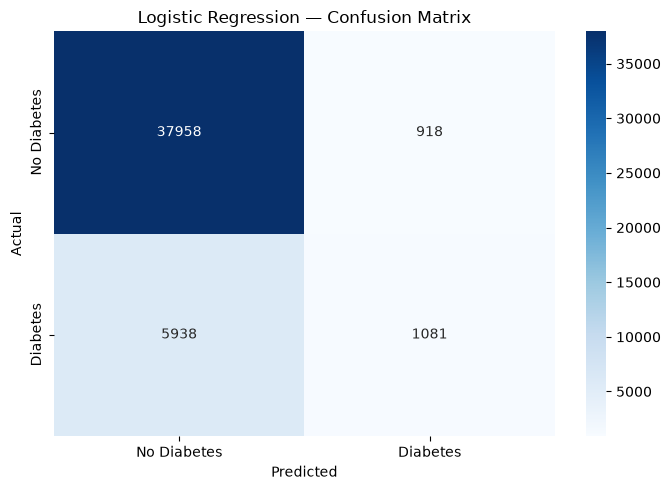

In [34]:
# ============================================================
# STEP 34 — CONFUSION MATRIX
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(
    y_test,
    y_pred
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "No Diabetes",
        "Diabetes"
    ],
    yticklabels=[
        "No Diabetes",
        "Diabetes"
    ]
)

plt.title("Logistic Regression — Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()

In [35]:
# ============================================================
# STEP 35 — STORE BASELINE RESULTS
# ============================================================

baseline_results = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "ROC_AUC": roc_auc,
        "PR_AUC": pr_auc
    }
])

baseline_results

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Logistic Regression,0.850616,0.54077,0.154011,0.239743,0.810203,0.414201


In [36]:
# ============================================================
# STEP 36 — RANDOM FOREST MODEL
# ============================================================

from sklearn.ensemble import RandomForestClassifier

random_forest_model = Pipeline(
    steps=[
        (
            "preprocessing",
            preprocessor
        ),
        (
            "model",
            RandomForestClassifier(
                n_estimators=300,
                random_state=42,
                n_jobs=-1,
                class_weight="balanced"
            )
        )
    ]
)

print("✅ Random Forest pipeline created.")

✅ Random Forest pipeline created.


In [37]:
# ============================================================
# STEP 37 — TRAIN RANDOM FOREST
# ============================================================

print("Training Random Forest...")

random_forest_model.fit(
    X_train,
    y_train
)

print("✅ Random Forest trained successfully!")

Training Random Forest...
✅ Random Forest trained successfully!


In [38]:
# ============================================================
# STEP 38 — RANDOM FOREST PREDICTIONS
# ============================================================

rf_pred = random_forest_model.predict(X_test)

rf_probability = (
    random_forest_model
    .predict_proba(X_test)[:, 1]
)

print("✅ Random Forest predictions generated!")

print("\nFirst 10 predictions:")
print(rf_pred[:10])

print("\nFirst 10 diabetes probabilities:")
print(
    np.round(
        rf_probability[:10],
        4
    )
)

✅ Random Forest predictions generated!

First 10 predictions:
[0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]

First 10 diabetes probabilities:
[0.295  0.02   0.226  0.0733 0.0467 0.45   0.2633 0.7493 0.0167 0.0189]


In [39]:
# ============================================================
# STEP 39 — RANDOM FOREST EVALUATION
# ============================================================

rf_accuracy = accuracy_score(
    y_test,
    rf_pred
)

rf_precision = precision_score(
    y_test,
    rf_pred,
    zero_division=0
)

rf_recall = recall_score(
    y_test,
    rf_pred,
    zero_division=0
)

rf_f1 = f1_score(
    y_test,
    rf_pred,
    zero_division=0
)

rf_roc_auc = roc_auc_score(
    y_test,
    rf_probability
)

rf_pr_auc = average_precision_score(
    y_test,
    rf_probability
)

print("=" * 65)
print("RANDOM FOREST RESULTS")
print("=" * 65)

print(f"\nAccuracy    : {rf_accuracy:.4f}")
print(f"Precision   : {rf_precision:.4f}")
print(f"Recall      : {rf_recall:.4f}")
print(f"F1 Score    : {rf_f1:.4f}")
print(f"ROC-AUC     : {rf_roc_auc:.4f}")
print(f"PR-AUC      : {rf_pr_auc:.4f}")

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        rf_pred,
        target_names=[
            "No Diabetes",
            "Diabetes"
        ],
        zero_division=0
    )
)

RANDOM FOREST RESULTS

Accuracy    : 0.8109
Precision   : 0.3943
Recall      : 0.4414
F1 Score    : 0.4165
ROC-AUC     : 0.7856
PR-AUC      : 0.3513

Classification Report:
              precision    recall  f1-score   support

 No Diabetes       0.90      0.88      0.89     38876
    Diabetes       0.39      0.44      0.42      7019

    accuracy                           0.81     45895
   macro avg       0.65      0.66      0.65     45895
weighted avg       0.82      0.81      0.82     45895



In [40]:
# ============================================================
# STEP 40 — MODEL COMPARISON
# ============================================================

random_forest_results = pd.DataFrame([
    {
        "Model": "Random Forest",
        "Accuracy": rf_accuracy,
        "Precision": rf_precision,
        "Recall": rf_recall,
        "F1": rf_f1,
        "ROC_AUC": rf_roc_auc,
        "PR_AUC": rf_pr_auc
    }
])

model_comparison = pd.concat(
    [
        baseline_results,
        random_forest_results
    ],
    ignore_index=True
)

model_comparison

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Logistic Regression,0.850616,0.540770,0.154011,0.239743,0.810203,0.414201
1,Random Forest,0.810873,0.394298,0.441373,0.416510,0.785628,0.351258


In [41]:
# ============================================================
# STEP 41 — MODEL COMPARISON SUMMARY
# ============================================================

comparison_display = model_comparison.copy()

metric_columns = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC_AUC",
    "PR_AUC"
]

comparison_display[metric_columns] = (
    comparison_display[metric_columns]
    .round(4)
)

comparison_display

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Logistic Regression,0.8506,0.5408,0.1540,0.2397,0.8102,0.4142
1,Random Forest,0.8109,0.3943,0.4414,0.4165,0.7856,0.3513


In [42]:
# ============================================================
# STEP 42 — CURRENT MODEL RANKING
# ============================================================

ranking = model_comparison.sort_values(
    by=["PR_AUC", "Recall", "F1"],
    ascending=False
).reset_index(drop=True)

print("Current model ranking")
print("=" * 60)

display(
    ranking.round(4)
)

print("\nCurrent best model based on PR-AUC:")
print(ranking.loc[0, "Model"])

Current model ranking


,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Logistic Regression,0.8506,0.5408,0.1540,0.2397,0.8102,0.4142
1,Random Forest,0.8109,0.3943,0.4414,0.4165,0.7856,0.3513



Current best model based on PR-AUC:
Logistic Regression


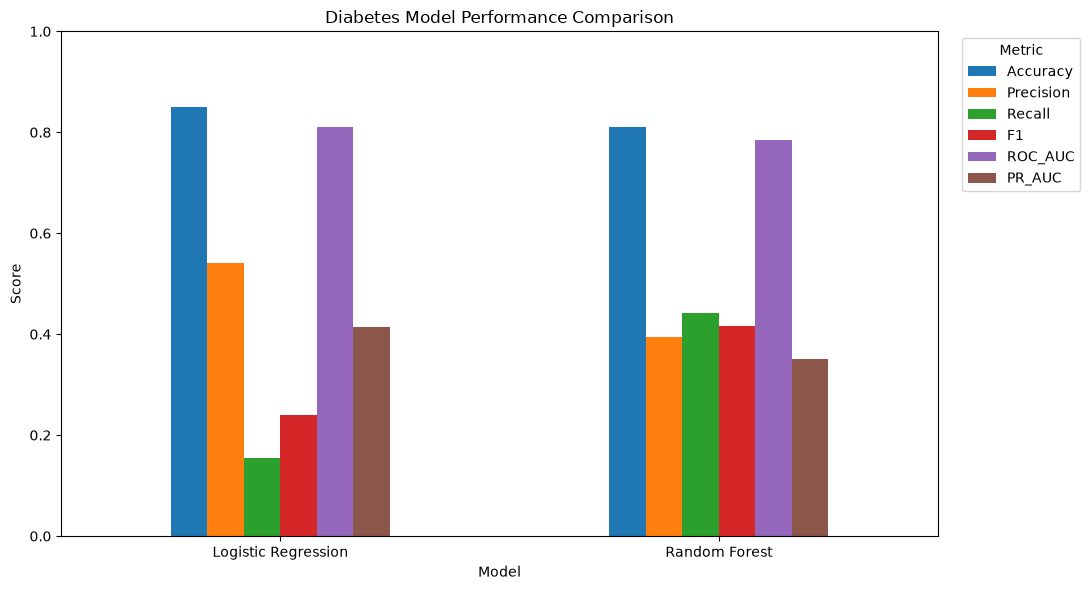

In [43]:
# ============================================================
# STEP 43 — MODEL PERFORMANCE COMPARISON
# ============================================================

metrics_to_plot = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC_AUC",
    "PR_AUC"
]

plot_data = model_comparison.set_index("Model")[metrics_to_plot]

ax = plot_data.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Diabetes Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)

plt.xticks(rotation=0)

plt.legend(
    title="Metric",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

In [44]:
# ============================================================
# STEP 45 — HISTOGRAM GRADIENT BOOSTING
# ============================================================

from sklearn.ensemble import HistGradientBoostingClassifier

gradient_boosting_model = Pipeline(
    steps=[
        (
            "preprocessing",
            preprocessor
        ),
        (
            "model",
            HistGradientBoostingClassifier(
                max_iter=200,
                learning_rate=0.08,
                max_leaf_nodes=31,
                random_state=42
            )
        )
    ]
)

print("✅ Gradient Boosting pipeline created.")

✅ Gradient Boosting pipeline created.


In [45]:
# ============================================================
# STEP 46 — TRAIN GRADIENT BOOSTING
# ============================================================

print("Training Gradient Boosting...")

gradient_boosting_model.fit(
    X_train,
    y_train
)

print("✅ Gradient Boosting trained successfully!")

Training Gradient Boosting...
✅ Gradient Boosting trained successfully!


In [46]:
# ============================================================
# STEP 47 — GRADIENT BOOSTING EVALUATION
# ============================================================

gb_pred = gradient_boosting_model.predict(X_test)

gb_probability = (
    gradient_boosting_model
    .predict_proba(X_test)[:, 1]
)

gb_accuracy = accuracy_score(
    y_test,
    gb_pred
)

gb_precision = precision_score(
    y_test,
    gb_pred,
    zero_division=0
)

gb_recall = recall_score(
    y_test,
    gb_pred,
    zero_division=0
)

gb_f1 = f1_score(
    y_test,
    gb_pred,
    zero_division=0
)

gb_roc_auc = roc_auc_score(
    y_test,
    gb_probability
)

gb_pr_auc = average_precision_score(
    y_test,
    gb_probability
)

gradient_boosting_results = pd.DataFrame([
    {
        "Model": "HistGradientBoosting",
        "Accuracy": gb_accuracy,
        "Precision": gb_precision,
        "Recall": gb_recall,
        "F1": gb_f1,
        "ROC_AUC": gb_roc_auc,
        "PR_AUC": gb_pr_auc
    }
])

print("=" * 65)
print("HISTOGRAM GRADIENT BOOSTING RESULTS")
print("=" * 65)

print(f"\nAccuracy    : {gb_accuracy:.4f}")
print(f"Precision   : {gb_precision:.4f}")
print(f"Recall      : {gb_recall:.4f}")
print(f"F1 Score    : {gb_f1:.4f}")
print(f"ROC-AUC     : {gb_roc_auc:.4f}")
print(f"PR-AUC      : {gb_pr_auc:.4f}")

HISTOGRAM GRADIENT BOOSTING RESULTS

Accuracy    : 0.8552
Precision   : 0.5970
Recall      : 0.1640
F1 Score    : 0.2573
ROC-AUC     : 0.8187
PR-AUC      : 0.4457


In [47]:
# ============================================================
# STEP 48 — FINAL BASELINE MODEL COMPARISON
# ============================================================

model_comparison = pd.concat(
    [
        baseline_results,
        random_forest_results,
        gradient_boosting_results
    ],
    ignore_index=True
)

model_comparison = model_comparison.sort_values(
    by="PR_AUC",
    ascending=False
).reset_index(drop=True)

display(
    model_comparison.round(4)
)

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,HistGradientBoosting,0.8552,0.5970,0.1640,0.2573,0.8187,0.4457
1,Logistic Regression,0.8506,0.5408,0.1540,0.2397,0.8102,0.4142
2,Random Forest,0.8109,0.3943,0.4414,0.4165,0.7856,0.3513


In [48]:
# ============================================================
# STEP 49 — CROSS-VALIDATION OF HISTGRADIENTBOOSTING
# ============================================================

from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = cross_validate(
    gradient_boosting_model,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "precision": "precision",
        "recall": "recall",
        "f1": "f1",
        "roc_auc": "roc_auc",
        "pr_auc": "average_precision"
    },
    n_jobs=-1
)

print("=" * 70)
print("5-FOLD CROSS-VALIDATION — HISTGRADIENTBOOSTING")
print("=" * 70)

for metric in [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "roc_auc",
    "pr_auc"
]:

    scores = cv_results[f"test_{metric}"]

    print(
        f"\n{metric.upper():10s}: "
        f"{scores.mean():.4f} ± {scores.std():.4f}"
    )

5-FOLD CROSS-VALIDATION — HISTGRADIENTBOOSTING

ACCURACY  : 0.8534 ± 0.0009

PRECISION : 0.5783 ± 0.0122

RECALL    : 0.1530 ± 0.0050

F1        : 0.2420 ± 0.0062

ROC_AUC   : 0.8148 ± 0.0011

PR_AUC    : 0.4322 ± 0.0055


In [49]:
# ============================================================
# STEP 50 — DECISION THRESHOLD ANALYSIS
# ============================================================

import numpy as np
import pandas as pd

thresholds = np.arange(
    0.10,
    0.71,
    0.05
)

threshold_results = []

for threshold in thresholds:

    threshold_pred = (
        y_probability >= threshold
    ).astype(int)

    threshold_results.append(
        {
            "Threshold": threshold,
            "Precision": precision_score(
                y_test,
                threshold_pred,
                zero_division=0
            ),
            "Recall": recall_score(
                y_test,
                threshold_pred,
                zero_division=0
            ),
            "F1": f1_score(
                y_test,
                threshold_pred,
                zero_division=0
            ),
            "Accuracy": accuracy_score(
                y_test,
                threshold_pred
            )
        }
    )

threshold_results = pd.DataFrame(
    threshold_results
)

display(
    threshold_results.round(4)
)

,Threshold,Precision,Recall,F1,Accuracy
0,0.10,0.2707,0.8779,0.4138,0.6195
1,0.15,0.3152,0.7696,0.4473,0.7091
2,0.20,0.3567,0.6625,0.4637,0.7657
3,0.25,0.3963,0.5592,0.4639,0.8023
4,0.30,0.4271,0.4549,0.4406,0.8233
5,0.35,0.4692,0.3642,0.4100,0.8397
6,0.40,0.4965,0.2821,0.3598,0.8465
7,0.45,0.5180,0.2110,0.2999,0.8493
8,0.50,0.5408,0.1540,0.2397,0.8506
9,0.55,0.5686,0.1051,0.1775,0.8509


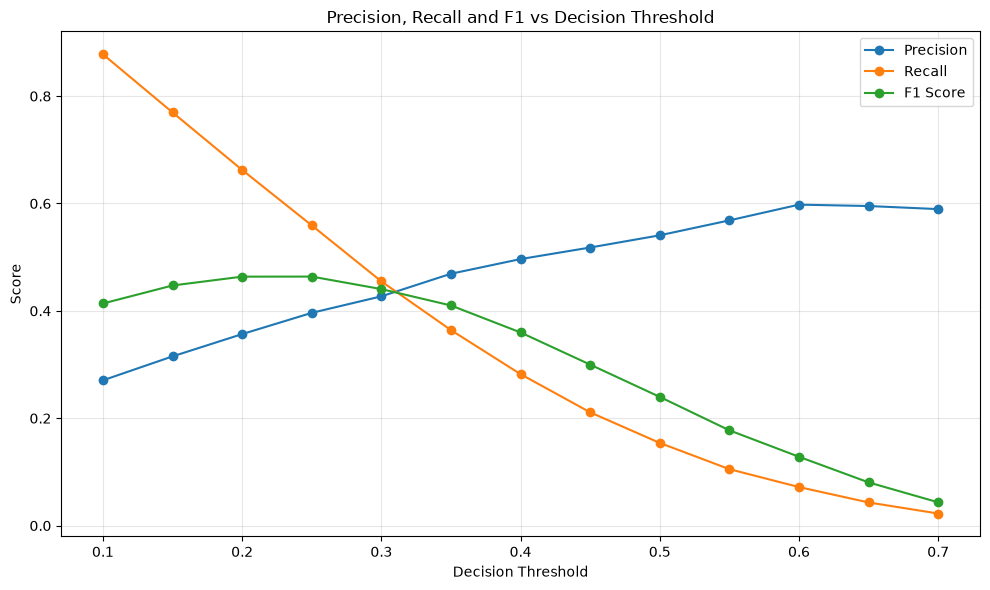

In [50]:
# ============================================================
# STEP 51 — PRECISION / RECALL VS THRESHOLD
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_results["Threshold"],
    threshold_results["F1"],
    marker="o",
    label="F1 Score"
)

plt.xlabel("Decision Threshold")
plt.ylabel("Score")

plt.title(
    "Precision, Recall and F1 vs Decision Threshold"
)

plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

In [51]:
# ============================================================
# STEP 52 — CREATE TRAINING AND VALIDATION SET
# ============================================================

from sklearn.model_selection import train_test_split

X_train_model, X_validation, y_train_model, y_validation = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("=" * 65)
print("TRAIN / VALIDATION / TEST SPLIT")
print("=" * 65)

print("\nModel training data:")
print("X_train_model:", X_train_model.shape)
print("y_train_model:", y_train_model.shape)

print("\nValidation data:")
print("X_validation:", X_validation.shape)
print("y_validation:", y_validation.shape)

print("\nFinal test data:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

TRAIN / VALIDATION / TEST SPLIT

Model training data:
X_train_model: (146863, 21)
y_train_model: (146863,)

Validation data:
X_validation: (36716, 21)
y_validation: (36716,)

Final test data:
X_test: (45895, 21)
y_test: (45895,)


In [52]:
# ============================================================
# STEP 53 — TRAIN HGB USING TRAINING DATA ONLY
# ============================================================

gradient_boosting_validation_model = Pipeline(
    steps=[
        (
            "preprocessing",
            preprocessor
        ),
        (
            "model",
            HistGradientBoostingClassifier(
                max_iter=200,
                learning_rate=0.08,
                max_leaf_nodes=31,
                random_state=42
            )
        )
    ]
)

print("Training HistGradientBoosting...")

gradient_boosting_validation_model.fit(
    X_train_model,
    y_train_model
)

print("✅ Model trained successfully!")

Training HistGradientBoosting...
✅ Model trained successfully!


In [53]:
# ============================================================
# STEP 54 — VALIDATION PREDICTIONS
# ============================================================

validation_probability = (
    gradient_boosting_validation_model
    .predict_proba(X_validation)[:, 1]
)

print("✅ Validation probabilities generated.")

print("\nFirst 10 validation probabilities:")
print(
    np.round(
        validation_probability[:10],
        4
    )
)

✅ Validation probabilities generated.

First 10 validation probabilities:
[0.1522 0.1242 0.3698 0.3942 0.1183 0.0162 0.1642 0.1418 0.1037 0.0518]


In [54]:
# ============================================================
# STEP 55 — VALIDATION THRESHOLD ANALYSIS
# ============================================================

thresholds = np.arange(
    0.10,
    0.71,
    0.01
)

validation_threshold_results = []

for threshold in thresholds:

    validation_pred = (
        validation_probability >= threshold
    ).astype(int)

    validation_threshold_results.append(
        {
            "Threshold": threshold,

            "Precision": precision_score(
                y_validation,
                validation_pred,
                zero_division=0
            ),

            "Recall": recall_score(
                y_validation,
                validation_pred,
                zero_division=0
            ),

            "F1": f1_score(
                y_validation,
                validation_pred,
                zero_division=0
            ),

            "Accuracy": accuracy_score(
                y_validation,
                validation_pred
            )
        }
    )

validation_threshold_results = pd.DataFrame(
    validation_threshold_results
)

display(
    validation_threshold_results.round(4)
)

,Threshold,Precision,Recall,F1,Accuracy
0,0.10,0.2746,0.8723,0.4178,0.6281
1,0.11,0.2837,0.8574,0.4263,0.6470
2,0.12,0.2923,0.8394,0.4337,0.6646
3,0.13,0.3012,0.8189,0.4404,0.6816
4,0.14,0.3084,0.8002,0.4453,0.6950
...,...,...,...,...,...
56,0.66,0.7371,0.0230,0.0446,0.8493
57,0.67,0.7407,0.0178,0.0348,0.8488
58,0.68,0.7589,0.0151,0.0297,0.8486
59,0.69,0.7500,0.0128,0.0252,0.8483


In [55]:
# ============================================================
# STEP 56 — SELECT CANDIDATE THRESHOLD
# ============================================================

minimum_recall = 0.50

eligible_thresholds = validation_threshold_results[
    validation_threshold_results["Recall"] >= minimum_recall
].copy()

if len(eligible_thresholds) > 0:

    best_threshold_row = (
        eligible_thresholds
        .sort_values(
            by=["F1", "Precision"],
            ascending=False
        )
        .iloc[0]
    )

    selected_threshold = float(
        best_threshold_row["Threshold"]
    )

    print("=" * 65)
    print("SELECTED CANDIDATE THRESHOLD")
    print("=" * 65)

    print(
        f"\nThreshold : {selected_threshold:.2f}"
    )

    print(
        f"Precision : {best_threshold_row['Precision']:.4f}"
    )

    print(
        f"Recall    : {best_threshold_row['Recall']:.4f}"
    )

    print(
        f"F1 Score  : {best_threshold_row['F1']:.4f}"
    )

    print(
        f"Accuracy  : {best_threshold_row['Accuracy']:.4f}"
    )

else:

    print(
        "No threshold achieved the required recall."
    )

    selected_threshold = 0.50

SELECTED CANDIDATE THRESHOLD

Threshold : 0.24
Precision : 0.3908
Recall    : 0.6166
F1 Score  : 0.4784
Accuracy  : 0.7943


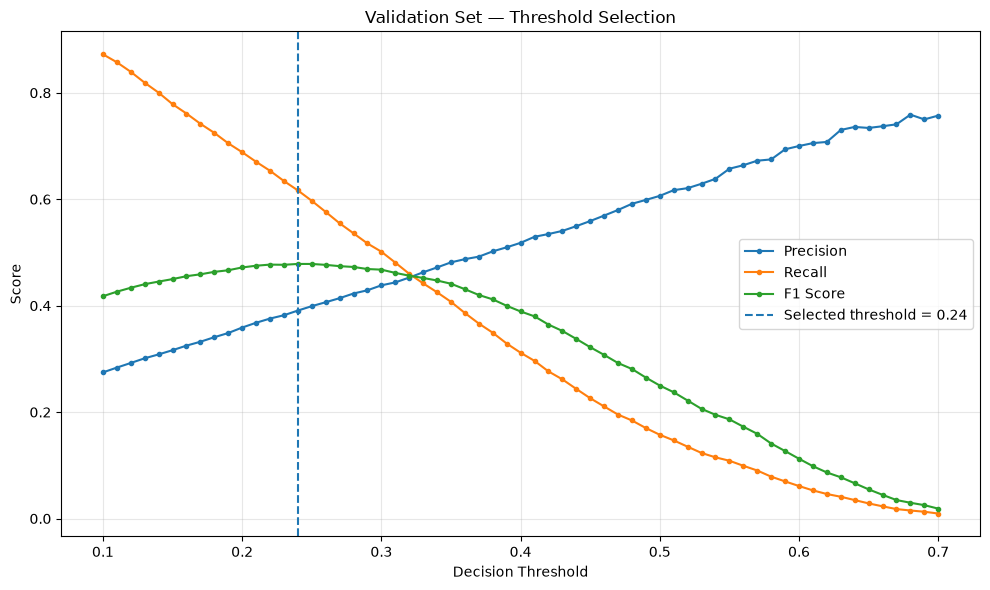

In [56]:
# ============================================================
# STEP 57 — VALIDATION THRESHOLD CURVES
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    validation_threshold_results["Threshold"],
    validation_threshold_results["Precision"],
    marker="o",
    markersize=3,
    label="Precision"
)

plt.plot(
    validation_threshold_results["Threshold"],
    validation_threshold_results["Recall"],
    marker="o",
    markersize=3,
    label="Recall"
)

plt.plot(
    validation_threshold_results["Threshold"],
    validation_threshold_results["F1"],
    marker="o",
    markersize=3,
    label="F1 Score"
)

plt.axvline(
    selected_threshold,
    linestyle="--",
    label=f"Selected threshold = {selected_threshold:.2f}"
)

plt.xlabel("Decision Threshold")
plt.ylabel("Score")

plt.title(
    "Validation Set — Threshold Selection"
)

plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

In [57]:
# ============================================================
# STEP 58 — HYPERPARAMETER TUNING
# ============================================================

from sklearn.model_selection import RandomizedSearchCV

print("=" * 65)
print("HYPERPARAMETER TUNING — HISTGRADIENTBOOSTING")
print("=" * 65)

hgb_pipeline = Pipeline(
    steps=[
        (
            "preprocessing",
            preprocessor
        ),
        (
            "model",
            HistGradientBoostingClassifier(
                random_state=42
            )
        )
    ]
)

param_distributions = {
    "model__max_iter": [
        100,
        150,
        200,
        300
    ],

    "model__learning_rate": [
        0.03,
        0.05,
        0.08,
        0.10
    ],

    "model__max_leaf_nodes": [
        15,
        31,
        63
    ],

    "model__l2_regularization": [
        0,
        0.1,
        1.0,
        5.0
    ]
}

hgb_search = RandomizedSearchCV(
    estimator=hgb_pipeline,
    param_distributions=param_distributions,
    n_iter=15,
    scoring="average_precision",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

print("\nStarting hyperparameter search...")

hgb_search.fit(
    X_train_model,
    y_train_model
)

print("\n✅ Hyperparameter tuning completed!")

print("\nBest parameters:")
print(hgb_search.best_params_)

print("\nBest cross-validation PR-AUC:")
print(
    round(
        hgb_search.best_score_,
        4
    )
)

HYPERPARAMETER TUNING — HISTGRADIENTBOOSTING

Starting hyperparameter search...
Fitting 3 folds for each of 15 candidates, totalling 45 fits

✅ Hyperparameter tuning completed!

Best parameters:
{'model__max_leaf_nodes': 15, 'model__max_iter': 300, 'model__learning_rate': 0.03, 'model__l2_regularization': 5.0}

Best cross-validation PR-AUC:
0.428


In [58]:
# ============================================================
# STEP 59 — TUNED MODEL VALIDATION
# ============================================================

best_hgb_model = hgb_search.best_estimator_

validation_probability_tuned = (
    best_hgb_model
    .predict_proba(X_validation)[:, 1]
)

validation_pred_tuned = (
    validation_probability_tuned >= selected_threshold
).astype(int)

print("=" * 65)
print("TUNED MODEL — VALIDATION PERFORMANCE")
print("=" * 65)

print(
    "\nAccuracy :",
    round(
        accuracy_score(
            y_validation,
            validation_pred_tuned
        ),
        4
    )
)

print(
    "Precision:",
    round(
        precision_score(
            y_validation,
            validation_pred_tuned,
            zero_division=0
        ),
        4
    )
)

print(
    "Recall   :",
    round(
        recall_score(
            y_validation,
            validation_pred_tuned,
            zero_division=0
        ),
        4
    )
)

print(
    "F1 Score :",
    round(
        f1_score(
            y_validation,
            validation_pred_tuned,
            zero_division=0
        ),
        4
    )
)

print(
    "ROC-AUC  :",
    round(
        roc_auc_score(
            y_validation,
            validation_probability_tuned
        ),
        4
    )
)

print(
    "PR-AUC   :",
    round(
        average_precision_score(
            y_validation,
            validation_probability_tuned
        ),
        4
    )
)

TUNED MODEL — VALIDATION PERFORMANCE

Accuracy : 0.7965
Precision: 0.3943
Recall   : 0.6159
F1 Score : 0.4808
ROC-AUC  : 0.8174
PR-AUC   : 0.4456


CONFUSION MATRIX — VALIDATION SET


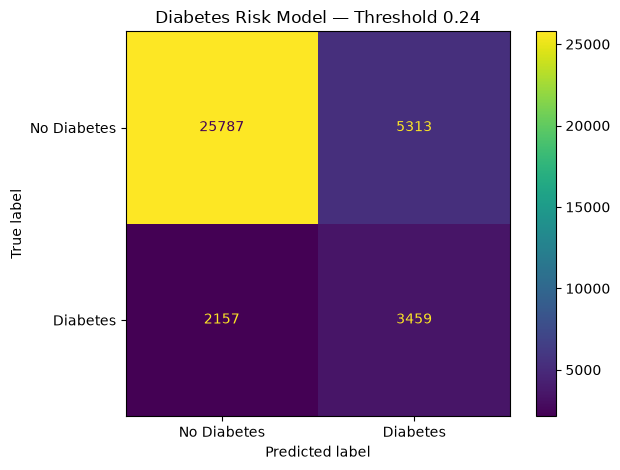

In [59]:
# ============================================================
# STEP 60 — CONFUSION MATRIX
# ============================================================

from sklearn.metrics import ConfusionMatrixDisplay

print("=" * 65)
print("CONFUSION MATRIX — VALIDATION SET")
print("=" * 65)

ConfusionMatrixDisplay.from_predictions(
    y_validation,
    validation_pred_tuned,
    display_labels=[
        "No Diabetes",
        "Diabetes"
    ],
    values_format="d"
)

plt.title(
    f"Diabetes Risk Model — Threshold {selected_threshold:.2f}"
)

plt.tight_layout()
plt.show()

In [60]:
# ============================================================
# STEP 61 — FINAL TEST SET EVALUATION
# ============================================================

print("=" * 70)
print("FINAL DIABETES MODEL — TEST SET EVALUATION")
print("=" * 70)

# Generate probability predictions on the untouched test set
test_probability = (
    best_hgb_model
    .predict_proba(X_test)[:, 1]
)

# Apply the threshold selected using the validation set
test_prediction = (
    test_probability >= selected_threshold
).astype(int)


# ------------------------------------------------------------
# Calculate final metrics
# ------------------------------------------------------------

test_accuracy = accuracy_score(
    y_test,
    test_prediction
)

test_precision = precision_score(
    y_test,
    test_prediction,
    zero_division=0
)

test_recall = recall_score(
    y_test,
    test_prediction,
    zero_division=0
)

test_f1 = f1_score(
    y_test,
    test_prediction,
    zero_division=0
)

test_roc_auc = roc_auc_score(
    y_test,
    test_probability
)

test_pr_auc = average_precision_score(
    y_test,
    test_probability
)


# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------

print("\nSelected threshold:", selected_threshold)

print("\nFINAL TEST RESULTS")
print("-" * 50)

print(f"Accuracy : {test_accuracy:.4f}")
print(f"Precision: {test_precision:.4f}")
print(f"Recall   : {test_recall:.4f}")
print(f"F1 Score : {test_f1:.4f}")
print(f"ROC-AUC  : {test_roc_auc:.4f}")
print(f"PR-AUC   : {test_pr_auc:.4f}")

FINAL DIABETES MODEL — TEST SET EVALUATION

Selected threshold: 0.23999999999999994

FINAL TEST RESULTS
--------------------------------------------------
Accuracy : 0.7917
Precision: 0.3867
Recall   : 0.6180
F1 Score : 0.4757
ROC-AUC  : 0.8186
PR-AUC   : 0.4452


FINAL CONFUSION MATRIX — TEST SET


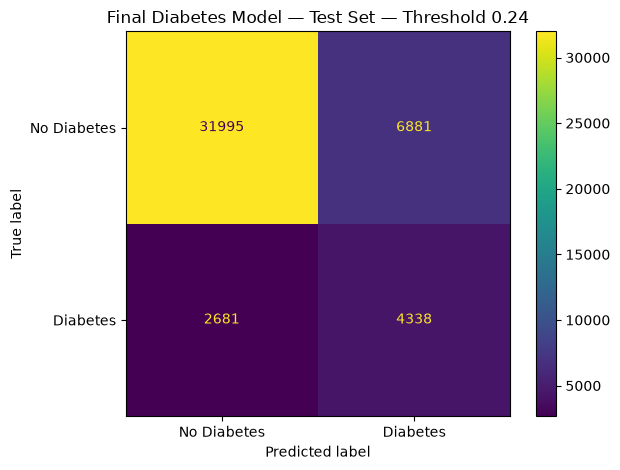

In [61]:
# ============================================================
# STEP 62 — FINAL TEST CONFUSION MATRIX
# ============================================================

from sklearn.metrics import ConfusionMatrixDisplay

print("=" * 70)
print("FINAL CONFUSION MATRIX — TEST SET")
print("=" * 70)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_prediction,
    display_labels=[
        "No Diabetes",
        "Diabetes"
    ],
    values_format="d"
)

plt.title(
    f"Final Diabetes Model — Test Set — Threshold {selected_threshold:.2f}"
)

plt.tight_layout()
plt.show()

In [62]:
# ============================================================
# STEP 63 — FINAL CLASSIFICATION REPORT
# ============================================================

from sklearn.metrics import classification_report

print("=" * 70)
print("FINAL CLASSIFICATION REPORT")
print("=" * 70)

print(
    classification_report(
        y_test,
        test_prediction,
        target_names=[
            "No Diabetes",
            "Diabetes"
        ],
        digits=4,
        zero_division=0
    )
)

FINAL CLASSIFICATION REPORT
              precision    recall  f1-score   support

 No Diabetes     0.9227    0.8230    0.8700     38876
    Diabetes     0.3867    0.6180    0.4757      7019

    accuracy                         0.7917     45895
   macro avg     0.6547    0.7205    0.6729     45895
weighted avg     0.8407    0.7917    0.8097     45895



DIABETES MODEL — PROBABILITY CALIBRATION

Brier Score:
0.1049


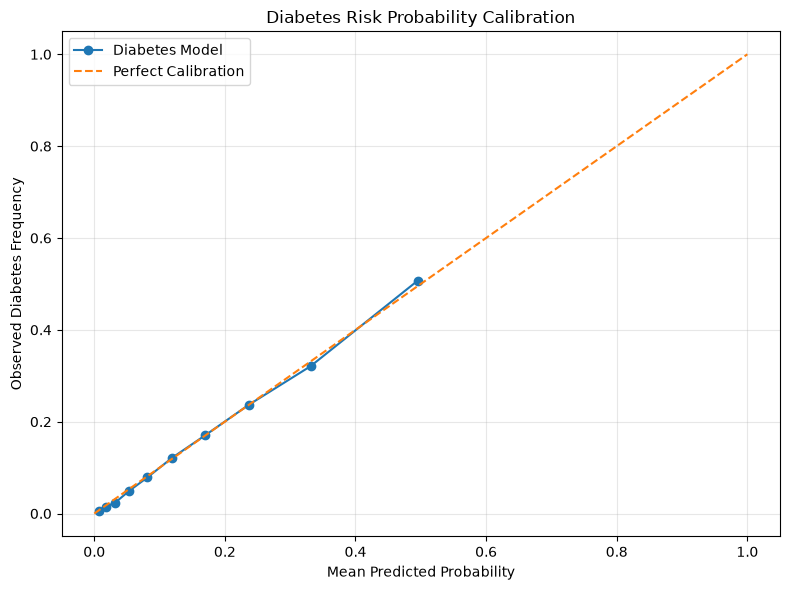

In [63]:
# ============================================================
# STEP 64 — PROBABILITY CALIBRATION
# ============================================================

from sklearn.metrics import brier_score_loss
from sklearn.calibration import calibration_curve

print("=" * 70)
print("DIABETES MODEL — PROBABILITY CALIBRATION")
print("=" * 70)

# Brier score
brier_score = brier_score_loss(
    y_test,
    test_probability
)

print("\nBrier Score:")
print(round(brier_score, 4))


# Calibration curve
prob_true, prob_pred = calibration_curve(
    y_test,
    test_probability,
    n_bins=10,
    strategy="quantile"
)


# Plot
plt.figure(figsize=(8, 6))

plt.plot(
    prob_pred,
    prob_true,
    marker="o",
    label="Diabetes Model"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect Calibration"
)

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Observed Diabetes Frequency")

plt.title("Diabetes Risk Probability Calibration")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

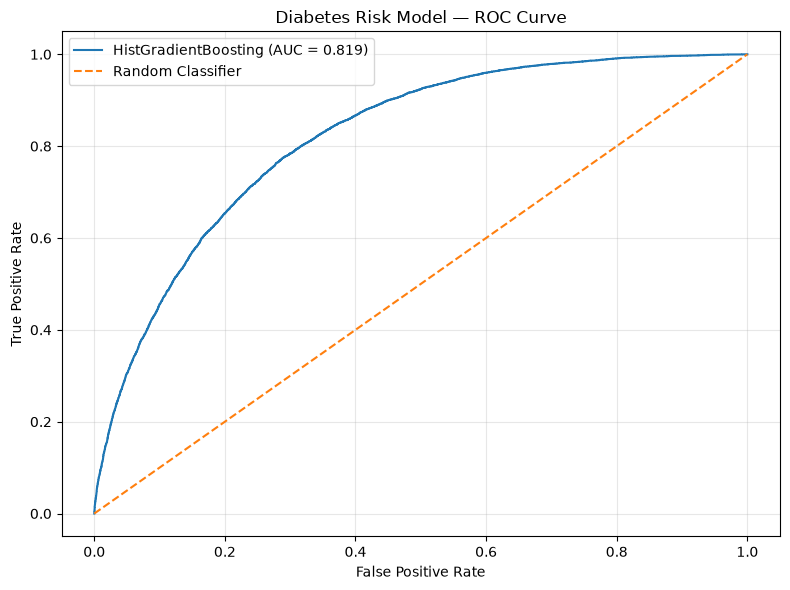

In [64]:
# ============================================================
# STEP 65 — ROC CURVE
# ============================================================

from sklearn.metrics import roc_curve

fpr, tpr, roc_thresholds = roc_curve(
    y_test,
    test_probability
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"HistGradientBoosting (AUC = {test_roc_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("Diabetes Risk Model — ROC Curve")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

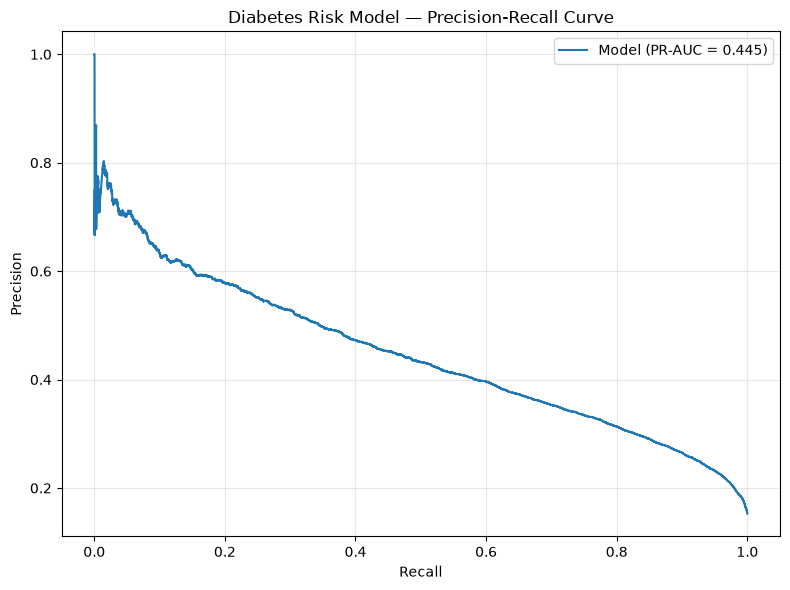

In [65]:
# ============================================================
# STEP 66 — PRECISION-RECALL CURVE
# ============================================================

from sklearn.metrics import precision_recall_curve

precision_values, recall_values, pr_thresholds = (
    precision_recall_curve(
        y_test,
        test_probability
    )
)

plt.figure(figsize=(8, 6))

plt.plot(
    recall_values,
    precision_values,
    label=f"Model (PR-AUC = {test_pr_auc:.3f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.title("Diabetes Risk Model — Precision-Recall Curve")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [66]:
# ============================================================
# STEP 67 — SHAP EXPLAINABLE AI SETUP
# ============================================================

import shap

print("=" * 70)
print("SHAP — EXPLAINABLE AI")
print("=" * 70)

# Get the trained preprocessing component
preprocessor_final = best_hgb_model.named_steps["preprocessing"]

# Get the trained HistGradientBoosting model
model_final = best_hgb_model.named_steps["model"]

print("\nPreprocessor:")
print(preprocessor_final)

print("\nModel:")
print(model_final)

print("\n✅ SHAP environment prepared.")

SHAP — EXPLAINABLE AI

Preprocessor:
ColumnTransformer(transformers=[('numeric', StandardScaler(),
                                 ['BMI', 'GenHlth', 'MentHlth', 'PhysHlth',
                                  'Age', 'Education', 'Income']),
                                ('binary', 'passthrough',
                                 ['HighBP', 'HighChol', 'CholCheck', 'Smoker',
                                  'Stroke', 'HeartDiseaseorAttack',
                                  'PhysActivity', 'Fruits', 'Veggies',
                                  'HvyAlcoholConsump', 'AnyHealthcare',
                                  'NoDocbcCost', 'DiffWalk', 'Sex'])])

Model:
HistGradientBoostingClassifier(l2_regularization=5.0, learning_rate=0.03,
                               max_iter=300, max_leaf_nodes=15,
                               random_state=42)

✅ SHAP environment prepared.


In [67]:
# ============================================================
# STEP 68 — TRANSFORM DATA FOR SHAP
# ============================================================

X_test_transformed = preprocessor_final.transform(X_test)

print("=" * 70)
print("SHAP DATA PREPARATION")
print("=" * 70)

print("\nOriginal test data shape:")
print(X_test.shape)

print("\nTransformed test data shape:")
print(X_test_transformed.shape)

SHAP DATA PREPARATION

Original test data shape:
(45895, 21)

Transformed test data shape:
(45895, 21)


In [68]:
# ============================================================
# STEP 69 — SHAP FEATURE NAMES
# ============================================================

try:
    feature_names_shap = (
        preprocessor_final
        .get_feature_names_out()
    )

except Exception:
    feature_names_shap = X_test.columns.to_numpy()


print("=" * 70)
print("SHAP FEATURE NAMES")
print("=" * 70)

print("\nNumber of features:", len(feature_names_shap))

print("\nFeature names:")

for i, feature in enumerate(feature_names_shap):
    print(i, "→", feature)

SHAP FEATURE NAMES

Number of features: 21

Feature names:
0 → numeric__BMI
1 → numeric__GenHlth
2 → numeric__MentHlth
3 → numeric__PhysHlth
4 → numeric__Age
5 → numeric__Education
6 → numeric__Income
7 → binary__HighBP
8 → binary__HighChol
9 → binary__CholCheck
10 → binary__Smoker
11 → binary__Stroke
12 → binary__HeartDiseaseorAttack
13 → binary__PhysActivity
14 → binary__Fruits
15 → binary__Veggies
16 → binary__HvyAlcoholConsump
17 → binary__AnyHealthcare
18 → binary__NoDocbcCost
19 → binary__DiffWalk
20 → binary__Sex


In [69]:
# ============================================================
# STEP 70 — CREATE SHAP EXPLAINER
# ============================================================

print("=" * 70)
print("CREATING SHAP EXPLAINER")
print("=" * 70)

explainer = shap.TreeExplainer(
    model_final
)

print("\n✅ SHAP TreeExplainer created successfully.")

CREATING SHAP EXPLAINER

✅ SHAP TreeExplainer created successfully.


In [70]:
# ============================================================
# STEP 71 — SHAP SAMPLE
# ============================================================

SHAP_SAMPLE_SIZE = 1000

X_shap = X_test_transformed[:SHAP_SAMPLE_SIZE]

print("=" * 70)
print("SHAP SAMPLE")
print("=" * 70)

print(
    "\nNumber of samples selected:",
    X_shap.shape[0]
)

print(
    "Number of features:",
    X_shap.shape[1]
)

SHAP SAMPLE

Number of samples selected: 1000
Number of features: 21


In [71]:
# ============================================================
# STEP 72 — CALCULATE SHAP VALUES
# ============================================================

print("=" * 70)
print("CALCULATING SHAP VALUES")
print("=" * 70)

shap_values = explainer.shap_values(
    X_shap
)

print("\n✅ SHAP values calculated.")

print(
    "\nSHAP values shape:",
    shap_values.shape
)

CALCULATING SHAP VALUES

✅ SHAP values calculated.

SHAP values shape: (1000, 21)


In [72]:
# ============================================================
# STEP 73 — GLOBAL SHAP FEATURE IMPORTANCE
# ============================================================

import numpy as np
import pandas as pd

# Mean absolute SHAP value for every feature
mean_abs_shap = np.abs(shap_values).mean(axis=0)

shap_importance = pd.DataFrame({
    "Feature": feature_names_shap,
    "Mean_Absolute_SHAP": mean_abs_shap
})

# Sort from most important to least important
shap_importance = (
    shap_importance
    .sort_values(
        "Mean_Absolute_SHAP",
        ascending=False
    )
    .reset_index(drop=True)
)

print("=" * 70)
print("GLOBAL SHAP FEATURE IMPORTANCE")
print("=" * 70)

display(
    shap_importance.round(4)
)

GLOBAL SHAP FEATURE IMPORTANCE


,Feature,Mean_Absolute_SHAP
0,numeric__GenHlth,0.4960
1,binary__HighBP,0.4524
2,numeric__Age,0.4082
3,numeric__BMI,0.3498
4,binary__HighChol,0.2969
5,binary__Sex,0.0966
6,numeric__Income,0.0966
7,binary__HvyAlcoholConsump,0.0725
8,binary__CholCheck,0.0706
9,numeric__MentHlth,0.0697


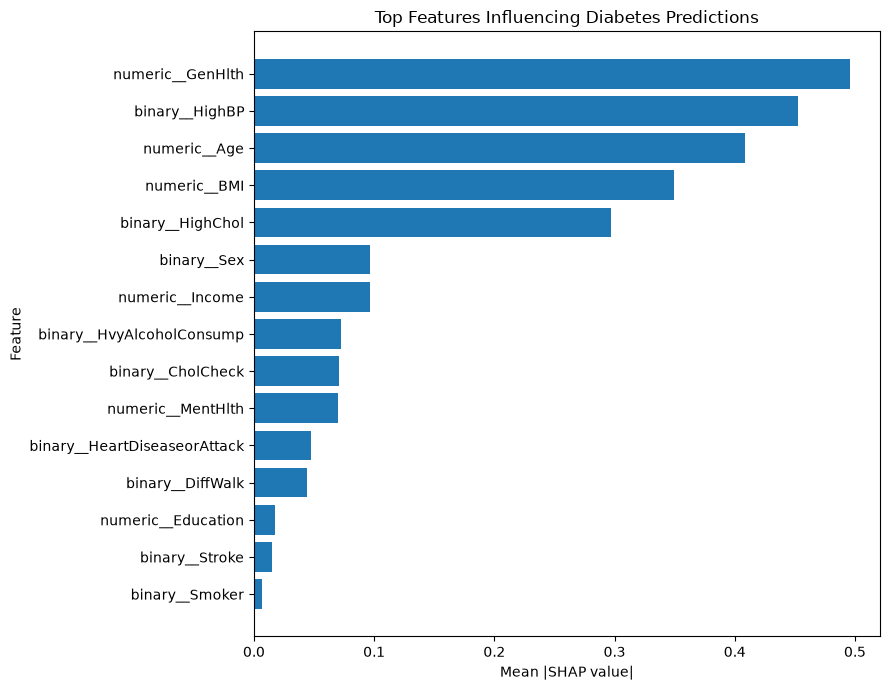

In [73]:
# ============================================================
# STEP 74 — SHAP FEATURE IMPORTANCE PLOT
# ============================================================

top_n = 15

top_features = (
    shap_importance
    .head(top_n)
    .sort_values(
        "Mean_Absolute_SHAP"
    )
)

plt.figure(figsize=(9, 7))

plt.barh(
    top_features["Feature"],
    top_features["Mean_Absolute_SHAP"]
)

plt.xlabel("Mean |SHAP value|")
plt.ylabel("Feature")

plt.title(
    "Top Features Influencing Diabetes Predictions"
)

plt.tight_layout()
plt.show()

SHAP SUMMARY PLOT


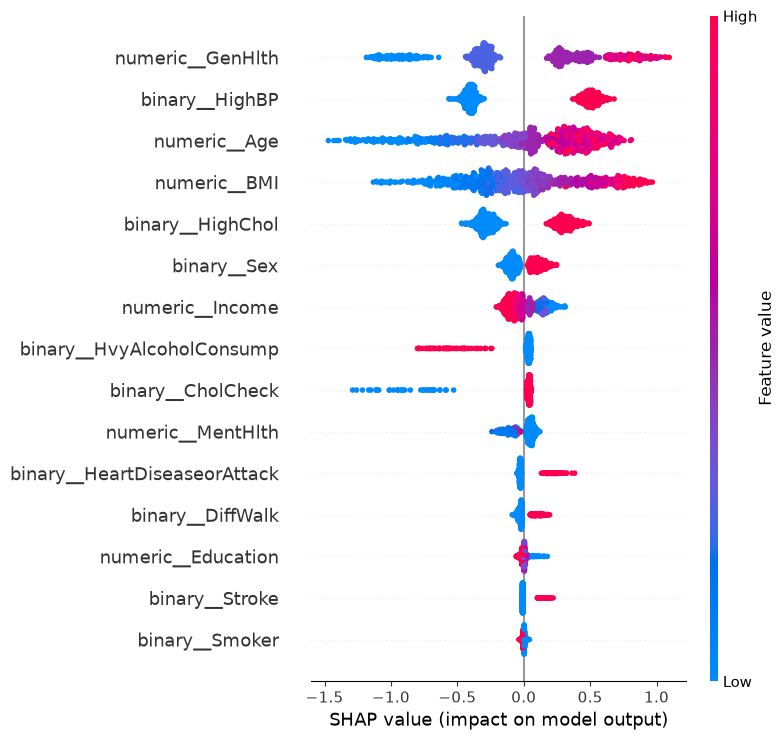

In [74]:
# ============================================================
# STEP 75 — SHAP SUMMARY PLOT
# ============================================================

print("=" * 70)
print("SHAP SUMMARY PLOT")
print("=" * 70)

shap.summary_plot(
    shap_values,
    X_shap,
    feature_names=feature_names_shap,
    max_display=15,
    show=True
)

In [75]:
# ============================================================
# STEP 76 — SHAP DIRECTION ANALYSIS
# ============================================================

shap_direction = pd.DataFrame({
    "Feature": feature_names_shap,
    "Mean_SHAP": shap_values.mean(axis=0),
    "Mean_Absolute_SHAP": np.abs(shap_values).mean(axis=0)
})

shap_direction = (
    shap_direction
    .sort_values(
        "Mean_Absolute_SHAP",
        ascending=False
    )
    .reset_index(drop=True)
)

print("=" * 70)
print("SHAP DIRECTION ANALYSIS")
print("=" * 70)

display(
    shap_direction
    .head(15)
    .round(4)
)

SHAP DIRECTION ANALYSIS


,Feature,Mean_SHAP,Mean_Absolute_SHAP
0,numeric__GenHlth,0.0081,0.4960
1,binary__HighBP,0.0246,0.4524
2,numeric__Age,0.0155,0.4082
3,numeric__BMI,-0.0042,0.3498
4,binary__HighChol,-0.0287,0.2969
5,binary__Sex,-0.0005,0.0966
6,numeric__Income,-0.0008,0.0966
7,binary__HvyAlcoholConsump,-0.0025,0.0725
8,binary__CholCheck,0.0059,0.0706
9,numeric__MentHlth,0.0017,0.0697


In [76]:
# ============================================================
# STEP 77 — INDIVIDUAL PATIENT SHAP EXPLANATION
# ============================================================

# Select one patient from the SHAP sample
patient_index = 0

patient_features = X_shap[patient_index:patient_index + 1]

patient_shap_values = shap_values[patient_index]

patient_probability = (
    best_hgb_model
    .predict_proba(X_test.iloc[[patient_index]])[:, 1][0]
)

patient_prediction = int(
    patient_probability >= selected_threshold
)

print("=" * 70)
print("INDIVIDUAL PATIENT — DIABETES RISK EXPLANATION")
print("=" * 70)

print("\nPatient index:", patient_index)

print(
    "\nEstimated diabetes probability:",
    f"{patient_probability:.2%}"
)

print(
    "Selected decision threshold:",
    f"{selected_threshold:.2f}"
)

print(
    "Model classification:",
    "Diabetes risk detected"
    if patient_prediction == 1
    else
    "Lower estimated diabetes risk"
)

INDIVIDUAL PATIENT — DIABETES RISK EXPLANATION

Patient index: 0

Estimated diabetes probability: 23.83%
Selected decision threshold: 0.24
Model classification: Lower estimated diabetes risk


In [77]:
# ============================================================
# STEP 78 — TOP INDIVIDUAL SHAP CONTRIBUTORS
# ============================================================

patient_explanation = pd.DataFrame({
    "Feature": feature_names_shap,
    "SHAP_Value": patient_shap_values,
    "Absolute_SHAP": np.abs(patient_shap_values)
})

patient_explanation = (
    patient_explanation
    .sort_values(
        "Absolute_SHAP",
        ascending=False
    )
    .reset_index(drop=True)
)

print("=" * 70)
print("TOP FACTORS IN THIS PATIENT'S PREDICTION")
print("=" * 70)

display(
    patient_explanation
    .head(10)
    .round(4)
)

TOP FACTORS IN THIS PATIENT'S PREDICTION


,Feature,SHAP_Value,Absolute_SHAP
0,numeric__Age,0.7391,0.7391
1,numeric__GenHlth,0.4270,0.4270
2,binary__HighBP,-0.3222,0.3222
3,binary__HeartDiseaseorAttack,0.2813,0.2813
4,binary__Sex,0.1664,0.1664
5,binary__HighChol,-0.1531,0.1531
6,numeric__Income,-0.0701,0.0701
7,binary__CholCheck,0.0493,0.0493
8,numeric__MentHlth,0.0478,0.0478
9,binary__HvyAlcoholConsump,0.0453,0.0453


In [78]:
# ============================================================
# STEP 79 — RISK-INCREASING / RISK-DECREASING FACTORS
# ============================================================

risk_increasing = (
    patient_explanation[
        patient_explanation["SHAP_Value"] > 0
    ]
    .head(5)
)

risk_decreasing = (
    patient_explanation[
        patient_explanation["SHAP_Value"] < 0
    ]
    .sort_values(
        "SHAP_Value",
        ascending=False
    )
    .head(5)
)

print("=" * 70)
print("FACTORS PUSHING PREDICTION TOWARD DIABETES")
print("=" * 70)

display(
    risk_increasing[
        ["Feature", "SHAP_Value"]
    ].round(4)
)

print("\n" + "=" * 70)
print("FACTORS PUSHING PREDICTION AWAY FROM DIABETES")
print("=" * 70)

display(
    risk_decreasing[
        ["Feature", "SHAP_Value"]
    ].round(4)
)

FACTORS PUSHING PREDICTION TOWARD DIABETES


,Feature,SHAP_Value
0,numeric__Age,0.7391
1,numeric__GenHlth,0.4270
3,binary__HeartDiseaseorAttack,0.2813
4,binary__Sex,0.1664
7,binary__CholCheck,0.0493



FACTORS PUSHING PREDICTION AWAY FROM DIABETES


,Feature,SHAP_Value
18,binary__Veggies,-0.0012
15,binary__PhysActivity,-0.0060
14,binary__Stroke,-0.0074
11,binary__DiffWalk,-0.0165
10,numeric__BMI,-0.0389


INDIVIDUAL SHAP WATERFALL

Patient index: 0
Estimated diabetes probability: 23.83%


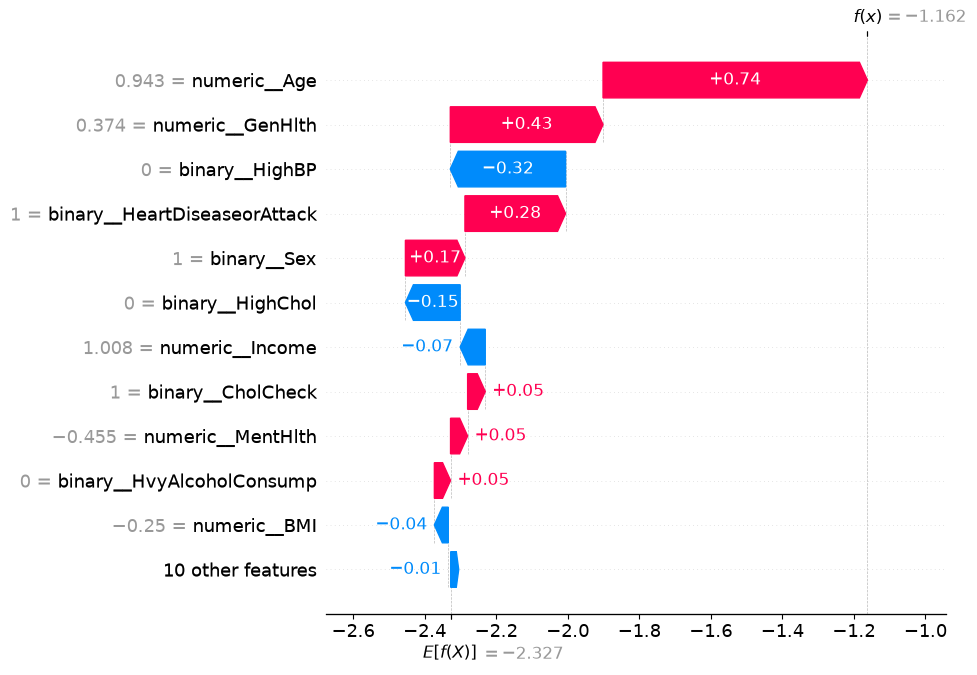

In [79]:
# ============================================================
# STEP 80 — INDIVIDUAL SHAP WATERFALL PLOT
# ============================================================

# Convert SHAP base value to a single scalar
base_value = np.asarray(
    explainer.expected_value
).reshape(-1)[0]

# Create explanation for one patient
patient_explanation_object = shap.Explanation(
    values=np.asarray(patient_shap_values).reshape(-1),
    base_values=float(base_value),
    data=np.asarray(patient_features[0]).reshape(-1),
    feature_names=list(feature_names_shap)
)

print("=" * 70)
print("INDIVIDUAL SHAP WATERFALL")
print("=" * 70)

print("\nPatient index:", patient_index)
print(
    "Estimated diabetes probability:",
    f"{patient_probability:.2%}"
)

# Display waterfall
shap.plots.waterfall(
    patient_explanation_object,
    max_display=12
)

In [81]:
# ============================================================
# STEP 81 — GLOBAL SHAP FEATURE IMPORTANCE
# ============================================================

print("=" * 70)
print("GLOBAL SHAP FEATURE IMPORTANCE")
print("=" * 70)

# Calculate mean absolute SHAP value for every feature
mean_abs_shap = np.abs(shap_values).mean(axis=0)

shap_global_importance = pd.DataFrame({
    "Feature": feature_names_shap,
    "Mean_Absolute_SHAP": mean_abs_shap
})

shap_global_importance = (
    shap_global_importance
    .sort_values(
        "Mean_Absolute_SHAP",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    shap_global_importance
    .head(15)
    .round(4)
)

GLOBAL SHAP FEATURE IMPORTANCE


,Feature,Mean_Absolute_SHAP
0,numeric__GenHlth,0.4960
1,binary__HighBP,0.4524
2,numeric__Age,0.4082
3,numeric__BMI,0.3498
4,binary__HighChol,0.2969
5,binary__Sex,0.0966
6,numeric__Income,0.0966
7,binary__HvyAlcoholConsump,0.0725
8,binary__CholCheck,0.0706
9,numeric__MentHlth,0.0697


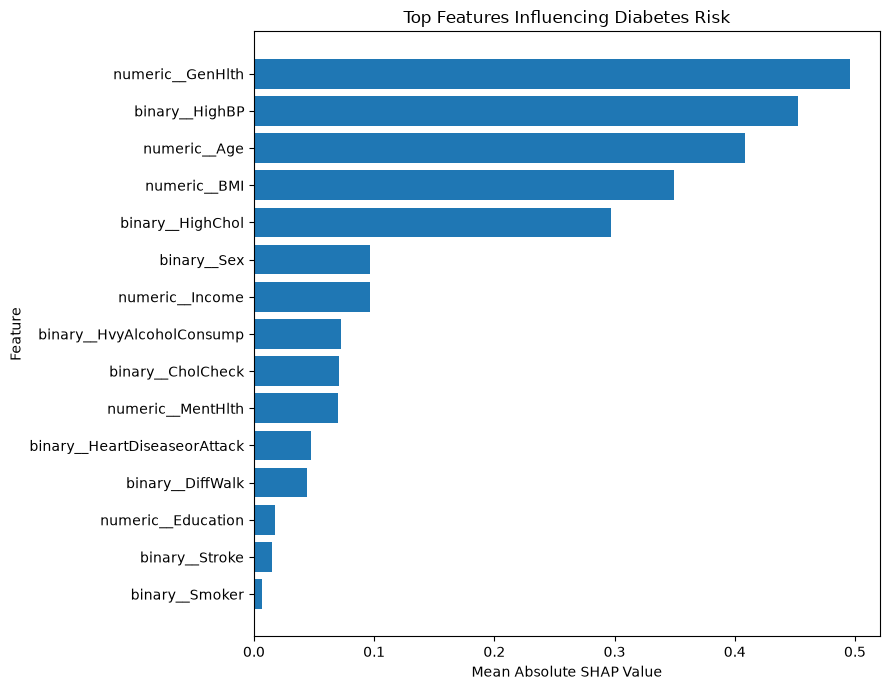

In [82]:
# ============================================================
# STEP 82 — GLOBAL SHAP IMPORTANCE PLOT
# ============================================================

top_features = (
    shap_global_importance
    .head(15)
    .sort_values("Mean_Absolute_SHAP")
)

plt.figure(figsize=(9, 7))

plt.barh(
    top_features["Feature"],
    top_features["Mean_Absolute_SHAP"]
)

plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Feature")
plt.title("Top Features Influencing Diabetes Risk")

plt.tight_layout()
plt.show()

In [83]:
# ============================================================
# STEP 83 — SAVE SHAP FEATURE IMPORTANCE
# ============================================================

from pathlib import Path

models_dir = Path("../models")
models_dir.mkdir(parents=True, exist_ok=True)

shap_global_importance.to_csv(
    models_dir / "diabetes_shap_importance.csv",
    index=False
)

print("SHAP feature importance saved successfully.")
print(
    "Saved to:",
    models_dir / "diabetes_shap_importance.csv"
)

SHAP feature importance saved successfully.
Saved to: ..\models\diabetes_shap_importance.csv


In [84]:
# ============================================================
# STEP 84 — SAVE SELECTED DECISION THRESHOLD
# ============================================================

import json

threshold_data = {
    "selected_threshold": float(selected_threshold)
}

threshold_path = models_dir / "diabetes_threshold.json"

with open(threshold_path, "w") as f:
    json.dump(threshold_data, f, indent=4)

print("=" * 70)
print("DECISION THRESHOLD SAVED")
print("=" * 70)

print(f"\nSelected threshold: {selected_threshold:.4f}")
print(f"Saved to: {threshold_path}")

DECISION THRESHOLD SAVED

Selected threshold: 0.2400
Saved to: ..\models\diabetes_threshold.json


In [85]:
# ============================================================
# STEP 85 — IDENTIFY FINAL TRAINED MODEL
# ============================================================

print("=" * 70)
print("CHECKING TRAINED MODELS")
print("=" * 70)

model_candidates = []

for name, value in list(globals().items()):
    if hasattr(value, "predict_proba") and hasattr(value, "fit"):
        model_candidates.append(
            (name, type(value).__name__)
        )

for name, model_type in model_candidates:
    print(f"{name}  -->  {model_type}")

CHECKING TRAINED MODELS
Pipeline  -->  ABCMeta
LogisticRegression  -->  type
logistic_model  -->  Pipeline
RandomForestClassifier  -->  ABCMeta
random_forest_model  -->  Pipeline
HistGradientBoostingClassifier  -->  ABCMeta
gradient_boosting_model  -->  Pipeline
gradient_boosting_validation_model  -->  Pipeline
RandomizedSearchCV  -->  ABCMeta
hgb_pipeline  -->  Pipeline
hgb_search  -->  RandomizedSearchCV
best_hgb_model  -->  Pipeline
model_final  -->  HistGradientBoostingClassifier


In [86]:
# ============================================================
# STEP 86 — SAVE FINAL DIABETES MODEL
# ============================================================

import joblib

model_path = models_dir / "diabetes_model.joblib"

joblib.dump(
    model_final,
    model_path
)

print("=" * 70)
print("FINAL DIABETES MODEL SAVED")
print("=" * 70)

print(f"\nModel: {type(model_final).__name__}")
print(f"Saved to: {model_path}")

FINAL DIABETES MODEL SAVED

Model: HistGradientBoostingClassifier
Saved to: ..\models\diabetes_model.joblib


In [87]:
# ============================================================
# STEP 87 — VERIFY SAVED MODEL
# ============================================================

loaded_diabetes_model = joblib.load(model_path)

print("=" * 70)
print("SAVED MODEL VERIFICATION")
print("=" * 70)

print("\nLoaded model:")
print(type(loaded_diabetes_model).__name__)

# Test prediction on one test patient
test_patient = X_test.iloc[[0]]

test_probability = loaded_diabetes_model.predict_proba(
    test_patient
)[0, 1]

print(
    f"\nTest patient diabetes probability: "
    f"{test_probability:.2%}"
)

print("\nModel loading and prediction successful.")

SAVED MODEL VERIFICATION

Loaded model:
HistGradientBoostingClassifier

Test patient diabetes probability: 27.48%

Model loading and prediction successful.


c:\Users\sanik\MedExplain_AI\ml\.venv\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but HistGradientBoostingClassifier was fitted without feature names
  warnings.warn(


In [88]:
# ============================================================
# STEP 88 — CHECK DIABETES MODEL FILES
# ============================================================

print("=" * 70)
print("DIABETES MODEL FILES")
print("=" * 70)

for file in sorted(models_dir.iterdir()):
    print(f"✓ {file.name}")

DIABETES MODEL FILES
✓ diabetes_model.joblib
✓ diabetes_shap_importance.csv
✓ diabetes_threshold.json
